# Electricity load forecast correction on Panama data

Select the project's **.venv** kernel and use **Restart Kernel → Run All**.
This notebook reads its own inputs and runs independently of
[00_data_analysis.ipynb](00_data_analysis.ipynb), which contains the source audit.
Tables, figures and conclusions stay in the notebook.

A base model predicts next-hour load. A second model predicts the base model's error.
Compare ordinary residual correction, past same-hour bias correction, and explanation
components weighted by their earlier realised benefit.

**Research questions**

1. Does XAI-based correction improve accuracy over simpler correction methods?
2. How does the choice of XAI method affect accuracy and added computation time?

All experiments currently use **Panama only**. Select settings on **2018–2019**, then
evaluate on the available **2020** observations. The source ends on 27 June 2020;
unavailable later hours are not evaluated. Train each model using earlier observations.
Models remain fixed during evaluation; feedback uses only already observed outcomes.

The combined XAI-plus-bias experiment reuses the same trained models and evaluation
hours. Its matched single-weight control receives the same extra bias layer.
These are retrospective comparisons on a previously examined period. The combined
experiment does not provide an independent confirmation on a new year or country.

**Limits.** Immediate measured-load availability is assumed. The 24-hour weather shift
does not match MERRA-2's actual release delay. Units and some interval metadata remain
unconfirmed. These assumptions limit interpretation as a real-time forecasting system.

**Outputs.** Displayed results were regenerated with the Panama-only configuration.


In [1]:
from pathlib import Path
from copy import deepcopy
import sys

sys.dont_write_bytecode = True
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/experiment.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

from utils.common import read_config
from utils.plotting import (
    ANALYSIS_SIZES, TALTECH_COLORS, analysis_barh, analysis_dates,
    analysis_grid, analysis_intervals, plot_style,
)
from utils.feature_engineering import (
    ERROR_FEATURES, feature_columns, known_error_features, load_dataset,
    load_panama_development, ramp_thresholds, split_year,
)
from utils.models import residual_forecasts
from utils.simple_correction import combined_forecasts
from utils.xai_comparison import EXPLAINERS, compare_explainers, explain_components
from utils.study import annual_forecast, oof_history, develop, policy_forecasts, validate_config
from utils.compare_forecasting_models import compare_models
from utils.evaluation import (clock_loss_interval, scope_masks, score_forecasts,
                            persistence_forecast, correction_diagnostics, prediction_metrics)

%matplotlib inline
pd.options.display.float_format = "{:.4f}".format

C:\Users\danyi\Desktop\TALTECH magister\Magistritöö\xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cfg = read_config()
validate_config(cfg)
DATASETS = tuple(cfg["datasets"])
COUNTRIES = {"panama": "Panama"}
METHODS = ("naive", "base", "residual", "hourly_bias", "credit_feedback")
BASELINES = ("naive", "base", "direct", "residual", "fixed", "scalar_adaptive",
             "standalone_feedback", "hourly_bias", "credit_feedback")
EXAMPLE_OFFSET_DAYS = 7
EXAMPLE_DAYS = 3
LABELS = {
    'naive': "Last hour's load", 'base': 'Base forecast', 'direct': 'Direct model',
    'residual': 'Base + correction', 'fixed': 'Fixed weight',
    'hourly_bias': 'Simple correction', 'credit_feedback': 'XAI correction',
    'scalar_adaptive': 'Adaptive weight', 'standalone_feedback': 'Separate credit',
    'matched_scalar': 'Single weight', 'matched_standalone': 'No interaction credit',
    'no_context': 'No hour grouping', 'mae_credit': 'Absolute-error credit',
    'recency_credit': 'Recent-weighted credit', 'tree_shap': 'TreeSHAP',
    'lime': 'LIME', 'feature_ablation': 'Group ablation',
    'xai_bias': 'XAI + simple correction', 'scalar_bias': 'Single weight + simple correction',
}
PLOT_LABELS = LABELS
PLOT_TITLES = {key: f"{COUNTRIES[key]} {cfg['datasets'][key]['test_year']}" for key in DATASETS}
PLOT_SCOPES = {'overall': 'All hours', 'rapid_increase': 'Rapid increase', 'rapid_decrease': 'Rapid decrease'}
PLOT_GROUPS = {
    'recent_load': 'Recent load', 'seasonal_load': 'Seasonal load', 'clock': 'Hour',
    'calendar': 'Calendar', 'weather': 'Weather', 'dynamics': 'Load changes',
    'forecast_anchor': 'Base forecast', 'error_memory': 'Past errors', 'offset': 'Offset',
}
GROUP_LABELS = PLOT_GROUPS
PLOT_COLORS = {
    'naive': TALTECH_COLORS['neutral'], 'base': TALTECH_COLORS['line'],
    'direct': TALTECH_COLORS['muted'], 'residual': TALTECH_COLORS['ink'],
    'hourly_bias': TALTECH_COLORS['burgundy'], 'credit_feedback': TALTECH_COLORS['accent'],
    'tree_shap': TALTECH_COLORS['accent'], 'lime': TALTECH_COLORS['cyan'],
    'feature_ablation': TALTECH_COLORS['muted'], 'matched_scalar': TALTECH_COLORS['cyan_dark'],
    'xai_bias': TALTECH_COLORS['ink_light'], 'scalar_bias': TALTECH_COLORS['cyan'],
}
XAI_OPTIONS = cfg["xai_comparison"]
XAI_LABELS = {key: LABELS[key] for key in ("residual", "hourly_bias", *EXPLAINERS)}
XAI_PAIRS = (("lime", "tree_shap"), ("feature_ablation", "tree_shap"),
             ("feature_ablation", "lime"), *((method, "hourly_bias") for method in EXPLAINERS))
COMBINED_LABELS = {key: LABELS[key] for key in
                   ("naive", "base", "residual", "hourly_bias", "credit_feedback",
                    "matched_scalar", "xai_bias", "scalar_bias")}
COMBINED_PAIRS = (("xai_bias", "hourly_bias"), ("xai_bias", "scalar_bias"),
                  ("xai_bias", "credit_feedback"), ("scalar_bias", "matched_scalar"))
DIAGNOSTIC_OPTIONS = cfg["diagnostics"]

display(pd.DataFrame([
    {"Dataset": COUNTRIES[d], "Development years": str(cfg["datasets"][d]["development_years"]),
     "Evaluation year": cfg["datasets"][d]["test_year"]} for d in DATASETS
]))
print("Base model:", cfg["base_model_family"], "| residual model: HistGBR")
print("Warm-up:", cfg["feedback"]["warmup_hours"], "h; minimum history:",
      cfg["feedback"]["min_history_points"], "observations per group.")


,Dataset,Development years,Evaluation year
0,Panama,"[2018, 2019]",2020


Base model: histgbr | residual model: HistGBR
Warm-up: 72 h; minimum history: 3 observations per group.


## 1. Prepare development inputs

Read the Panama CSV through the same helper used by the data-overview notebook.
Exclude the evaluation year from the development input. Set rapid-change thresholds
using targets before the first development year. Actual changes label evaluation groups
only; they are not model inputs.


In [3]:
panama_options = cfg["datasets"]["panama"]
panama_development, quality = load_panama_development(ROOT / panama_options["path"], cfg)
base_columns, correction_columns = feature_columns("panama")
panama_thresholds = ramp_thresholds(panama_development, panama_options["threshold_end"])


## 2. Compare base models

Compare Ridge, Random Forest, GBR and HistGBR using identical inputs and forecast hours
on the two development years. Fit preprocessing on training data only. Use one fixed
configuration per model family. The table supports the base-model choice but does not
automatically change the configured model.


In [4]:
preliminary, preliminary_folds, preliminary_boundaries = compare_models(panama_development, cfg)
display(preliminary[["model", "n", *[f"MAE_{year}" for year in panama_options["development_years"]], "MAE", "RMSE", "bias"]])
print("Lowest development MAE:", preliminary.iloc[0].model)
print("Configured base model:", cfg["base_model_family"])

Development 2018: Ridge


Development 2018: RandomForest


Development 2018: GBR


Development 2018: HistGBR


Development 2019: Ridge


Development 2019: RandomForest


Development 2019: GBR


Development 2019: HistGBR


,model,n,MAE_2018,MAE_2019,MAE,RMSE,bias
0,HistGBR,17520,13.8817,19.3317,16.6067,25.6586,-1.4890
1,RandomForest,17520,15.0092,22.2582,18.6337,29.6843,-1.7600
2,GBR,17520,17.9250,24.5936,21.2593,30.8325,-2.4997
3,Ridge,17520,29.2048,30.8666,30.0357,39.8541,3.2776


Lowest development MAE: HistGBR
Configured base model: histgbr


## 3. Historical forecast errors

Predict each year with a model trained only on earlier years. These temporal
out-of-fold (OOF) forecasts exclude the evaluated target from training. The residual
model learns from the errors of those forecasts.


In [5]:
with threadpool_limits(limits=cfg["workers"]):
    panama_history = oof_history(
        panama_development, panama_options["test_year"], base_columns, cfg
    )
display(panama_history.groupby(panama_history.target_time.dt.year).size().to_frame("OOF hours"))

  Base OOF 2016: 8784 forecasts


  Base OOF 2017: 8760 forecasts


  Base OOF 2018: 8760 forecasts


  Base OOF 2019: 8760 forecasts


,OOF hours
target_time,
2016,8784
2017,8760
2018,8760
2019,8760


## 4. Select correction settings

The simple method adjusts the residual forecast using past mean errors at the same
hour. The XAI method weights explanation parts using their earlier realised credit.
Select memory windows and strengths only on Panama 2018–2019.

Selection considers MAE in both years and in each scenario, with a limit on degradation.
Controls include fixed weights, one adaptive weight, simpler credit and decaying memory.
The `identity` candidate leaves the ordinary residual forecast unchanged.


In [6]:
with threadpool_limits(limits=cfg["workers"]):
    development_results, choices, decay, development_folds = develop(
        panama_history, correction_columns, panama_thresholds, cfg, return_folds=True
    )
selection = {"choices": deepcopy(choices), "decay": deepcopy(decay)}
choice_rows = []
for method, choice in choices.items():
    setting = choice["setting"] or {}
    choice_rows.append({
        "Method": LABELS[method], "Candidate": choice["candidate"],
        "Window (h)": setting.get("window_hours"), "Strength": setting.get("strength"),
        "Same hour": setting.get("by_hour", True),
        "Development MAE ratio": choice["development_ratio"],
    })
display(pd.DataFrame(choice_rows))
print("Selected memory decay:", decay)
print("Settings recorded before evaluation; the period has been examined before.")

  Development 2018: evaluated fixed and adaptive policies


  Development 2019: evaluated fixed and adaptive policies


,Method,Candidate,Window (h),Strength,Same hour,Development MAE ratio
0,Fixed weight,identity,NaN,NaN,True,1.0000
1,Simple correction,hourly_bias_w168_s0.25,168.0000,0.2500,True,0.9887
2,Adaptive weight,scalar_adaptive_w168_h1_s0.25,168.0000,0.2500,True,0.9975
3,Separate credit,standalone_feedback_w168_h1_s1.0,168.0000,1.0000,True,0.9948
4,XAI correction,credit_feedback_w168_h1_s1.0,168.0000,1.0000,True,0.9925


Selected memory decay: {'candidate': 'decay_168', 'half_life_hours': 168, 'development_ratio': 0.9920089907648113, 'memory': 'exponential'}
Settings recorded before evaluation; the period has been examined before.


## 5. Combined correction and comparison plan

**Idea:** explanation-component weighting and overall forecast bias correction may
complement each other. Add a same-hour correction based on the XAI forecast's own
past errors. A matched no-XAI control weights the entire residual correction with one
weight and receives the same second layer based on its own errors.

Reuse the settings selected on 2018–2019 and the existing development models. No new
parameter search is performed. The development comparison is descriptive.

Record the model configuration, both correction settings, warm-up policy and four
comparison pairs before applying the combined methods to the available Panama 2020
hours. The main endpoint is overall MAE. The combined XAI method must outperform both
simple correction and the matched combined single-weight control to support added
value in this comparison. Four pairs and three scopes give 12 adjusted comparisons;
the primary block is 168 hours and the sensitivity block is 24 hours.

Panama 2020 has been examined before. Fixing this configuration now does not turn this
retrospective extension into an independent confirmation. Do not retune from its results.


In [7]:
combined_protocol = deepcopy({
    "dataset": cfg["combined_correction"]["dataset"],
    "test_year": cfg["datasets"][cfg["combined_correction"]["dataset"]]["test_year"],
    "xai_setting": choices["credit_feedback"]["setting"],
    "bias_setting": choices["hourly_bias"]["setting"],
    "feedback": cfg["feedback"], "base_model_family": cfg["base_model_family"],
    "base_model": cfg["base_model"], "residual_model": cfg["residual_model"],
    "seed": cfg["seed"], "load_delay_hours": cfg["load_delay_hours"],
    "weather_delay_hours": cfg["weather_delay_hours"], "evaluation": cfg["evaluation"],
    "threshold_end": cfg["datasets"][cfg["combined_correction"]["dataset"]]["threshold_end"], "pairs": COMBINED_PAIRS,
})
combined_protocol_snapshot = deepcopy(combined_protocol)
combined_development_parts = []
with threadpool_limits(limits=cfg["workers"]):
    for valid_dev, components_dev, fitted_dev in development_folds:
        frame_dev = valid_dev.assign(prediction_residual=fitted_dev["residual"])
        predictions_dev = combined_forecasts(
            frame_dev, components_dev, combined_protocol["xai_setting"],
            combined_protocol["bias_setting"], combined_protocol["feedback"],
        )
        combined_development_parts.append(score_forecasts(
            frame_dev, predictions_dev, panama_thresholds, cfg, "development"
        ))
combined_development = pd.concat(combined_development_parts, ignore_index=True)
assert set(combined_development.year) == set(cfg["datasets"]["panama"]["development_years"])
assert combined_development.stage.eq("development").all()
display(combined_development[combined_development.scope.eq("overall")].assign(
    Method=lambda x: x.method.map(COMBINED_LABELS)
)[["year", "Method", "n", "MAE", "RMSE", "bias"]].rename(columns={
    "year": "Year", "n": "Hours", "bias": "Bias",
}))
dev_comparison = combined_development.pivot(index=["year", "scope"], columns="method", values="MAE")
display(pd.DataFrame({
    "XAI + bias minus simple correction": dev_comparison.xai_bias - dev_comparison.hourly_bias,
    "XAI + bias minus single weight + bias": dev_comparison.xai_bias - dev_comparison.scalar_bias,
}))
print("Recorded retrospective comparison configuration:", combined_protocol)


,Year,Method,Hours,MAE,RMSE,Bias
0,2018,Base forecast,8760,13.7729,18.5976,-1.6453
3,2018,Base + correction,8760,12.6234,16.9642,-1.2829
6,2018,Simple correction,8760,12.4980,16.8301,-0.9690
9,2018,XAI correction,8760,12.4324,16.6971,-0.8648
12,2018,Single weight,8760,12.5872,16.8719,-1.2720
15,2018,XAI + simple correction,8760,12.4600,16.7331,-0.6560
18,2018,Single weight + simple correction,8760,12.4894,16.7712,-0.9611
21,2019,Base forecast,8760,19.2399,31.0780,-1.4865
24,2019,Base + correction,8760,15.7176,26.8298,-1.5946
27,2019,Simple correction,8760,15.4852,26.5223,-1.1983


XAI + bias minus simple correction  \
year scope                                                
2018 overall                                    -0.0380   
     rapid_decrease                             -0.0160   
     rapid_increase                              0.0708   
2019 overall                                     0.0150   
     rapid_decrease                              0.2493   
     rapid_increase                             -0.0423   

                     XAI + bias minus single weight + bias  
year scope                                                  
2018 overall                                       -0.0295  
     rapid_decrease                                -0.0505  
     rapid_increase                                 0.2225  
2019 overall                                       -0.0561  
     rapid_decrease                                 0.1620  
     rapid_increase                                -0.0650

Recorded retrospective comparison configuration: {'dataset': 'panama', 'test_year': 2020, 'xai_setting': {'window_hours': 168, 'by_hour': True, 'strength': 1.0}, 'bias_setting': {'window_hours': 168, 'strength': 0.25}, 'feedback': {'min_history_points': 3, 'warmup_hours': 72}, 'base_model_family': 'histgbr', 'base_model': {'n_estimators': 120, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 30, 'loss': 'squared_error'}, 'residual_model': {'max_iter': 180, 'learning_rate': 0.06, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.0, 'early_stopping': False}, 'seed': 42, 'load_delay_hours': 0, 'weather_delay_hours': 24, 'evaluation': {'bootstrap_blocks_hours': [24, 168], 'primary_block_hours': 168, 'bootstrap_repeats': 5000, 'harm_tolerance': 1e-09}, 'threshold_end': '2018-01-01', 'pairs': (('xai_bias', 'hourly_bias'), ('xai_bias', 'scalar_bias'), ('xai_bias', 'credit_feedback'), ('scalar_bias', 'matched_scalar'))}


## 6. Train the evaluation models

Train the Panama base and residual models on earlier data. All correction methods
share those models and evaluation rows. Only feedback changes during the evaluation
period. The source ends in June 2020; unavailable hours are excluded, not filled in.
Panama timestamps and hour groups are interpreted as local time without a timezone
offset, as documented in the source audit.


In [8]:
runs, metric_parts, coverage = {}, [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        options = cfg["datasets"][dataset]
        frame, quality = load_dataset(ROOT / options["path"], cfg, dataset)
        base_columns, correction_columns = feature_columns(dataset)
        history = (panama_history if dataset == "panama" else
                   oof_history(frame, options["test_year"], base_columns, cfg))
        hold = annual_forecast(frame, options["test_year"], base_columns, cfg)
        combined = pd.concat(
            [history.drop(columns=ERROR_FEATURES), hold], ignore_index=True
        )
        combined = pd.concat([combined, known_error_features(combined)], axis=1)
        train, valid = split_year(combined, options["test_year"])
        fitted_forecasts, components, inputs, residual_model = residual_forecasts(
            train, valid, correction_columns, cfg, return_model=True
        )
        forecasts, traces = policy_forecasts(
            valid, fitted_forecasts, components, selection, cfg
        )
        forecasts["naive"] = persistence_forecast(valid)
        weights = traces["credit_feedback"]
        effective = components * weights
        thresholds = ramp_thresholds(frame, options["threshold_end"])
        assert train.target_time.max() <= valid.origin_time.min()
        assert valid.target_time.is_unique
        assert np.isfinite(np.column_stack(list(forecasts.values()))).all()
        valid["prediction_residual"] = forecasts["residual"]
        runs[dataset] = {"residual_model": residual_model, "training": train, "inputs": inputs,
                         "frame": valid, "forecasts": forecasts, "weights": weights,
                         "components": components, "effective": effective,
                         "thresholds": thresholds}
        metric_parts.append(score_forecasts(
            valid, forecasts, thresholds, cfg, "final"
        ).assign(dataset=dataset))
        coverage.append({
            "Dataset": COUNTRIES[dataset], "First target": valid.target_time.min(),
            "Last target": valid.target_time.max(), "Evaluated hours": len(valid),
            "Calendar hours in year": quality["calendar_test_hours"],
            "Unscored hours": quality["unscored_test_hours"],
            "Last training target": train.target_time.max(),
        })

assert choices == selection["choices"]
metrics = pd.concat(metric_parts, ignore_index=True)
display(pd.DataFrame(coverage))

  Base OOF 2020: 4273 forecasts


,Dataset,First target,Last target,Evaluated hours,Calendar hours in year,Unscored hours,Last training target
0,Panama,2020-01-01,2020-06-27,4273,8784,4511,2019-12-31 23:00:00


## 7. Overall accuracy

**MAE** is mean absolute error; **RMSE** gives greater weight to large errors.
**Bias** is predicted minus observed load: positive values indicate overprediction.
Smaller MAE and RMSE are better. Values remain in the source-data units.
`identity` leaves the ordinary residual correction unchanged.


In [9]:
overall = metrics[metrics.scope.eq("overall")].copy()
assert overall.groupby("dataset").n.nunique().eq(1).all()
overall_view = overall[overall.method.isin(BASELINES)].assign(
    Dataset=overall.dataset.map(COUNTRIES), Method=overall.method.map(LABELS)
)[["Dataset", "Method", "n", "MAE", "RMSE", "bias", "improvement_vs_residual_pct"]]
display(overall_view.rename(columns={
    "n": "Hours", "bias": "Bias",
    "improvement_vs_residual_pct": "MAE gain over residual (%)",
}))

,Dataset,Method,Hours,MAE,RMSE,Bias,MAE gain over residual (%)
0,Panama,Base forecast,4273,20.4511,27.1860,-0.3301,-22.8250
3,Panama,Direct model,4273,17.6173,23.6014,-0.0696,-5.8056
6,Panama,Base + correction,4273,16.6506,22.2651,0.9595,0.0000
9,Panama,Simple correction,4273,15.7702,21.1909,0.7312,5.2875
12,Panama,Fixed weight,4273,16.6506,22.2651,0.9595,0.0000
15,Panama,Adaptive weight,4273,16.6227,22.2090,0.8420,0.1678
18,Panama,Separate credit,4273,15.7654,21.2128,0.3342,5.3165
21,Panama,XAI correction,4273,15.7765,21.2161,0.2676,5.2498
66,Panama,Last hour's load,4273,38.0704,49.2074,0.0166,-128.6431


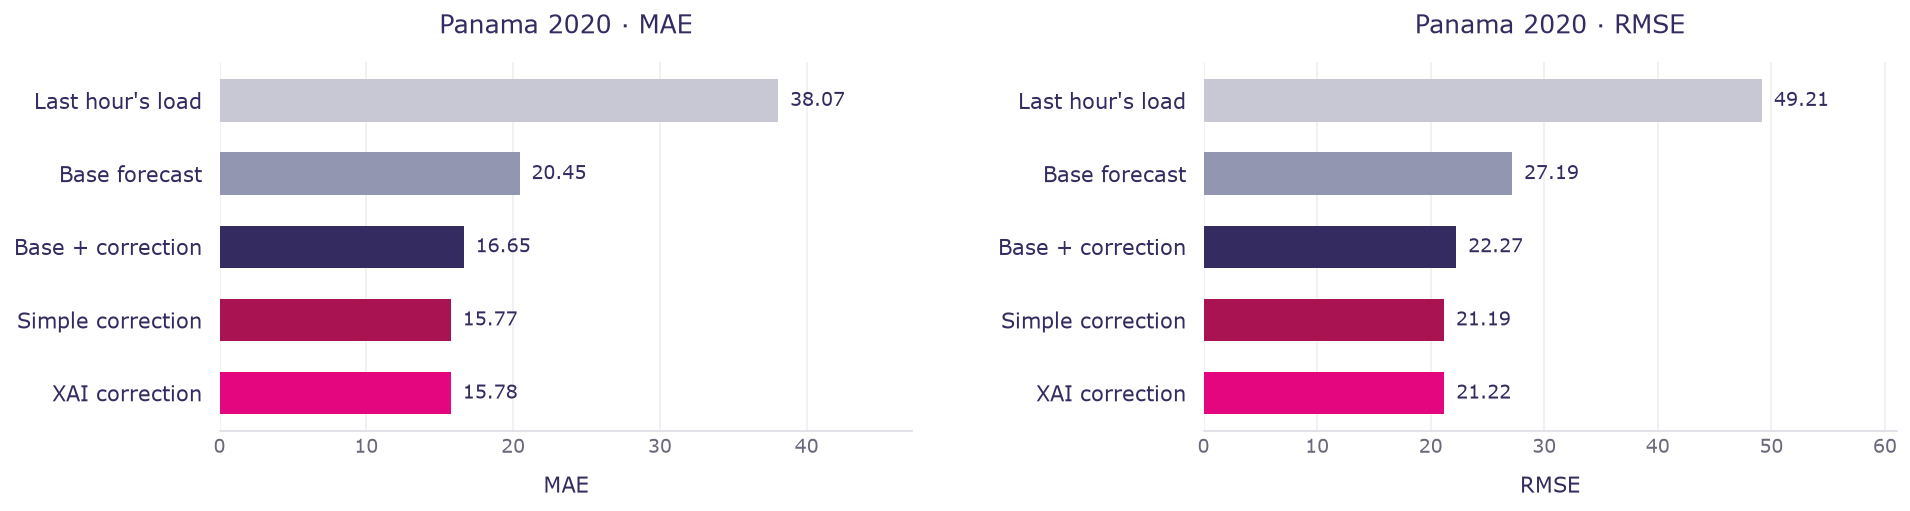

In [10]:
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 4 * len(DATASETS)), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        values = overall[overall.dataset.eq(dataset)].set_index('method').loc[list(METHODS)]
        for col, metric in enumerate(('MAE', 'RMSE')):
            ax = axes[row, col]
            analysis_barh(ax, [PLOT_LABELS[m] for m in METHODS], values[metric],
                          [PLOT_COLORS[m] for m in METHODS])
            ax.set(title=f'{PLOT_TITLES[dataset]} · {metric}', xlabel=metric)
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=3)
    plt.show()


## 8. Monthly performance

Monthly MAE shows when corrections help or harm. The plots cover only months available
in the source. Do not change settings after inspecting these evaluation results.


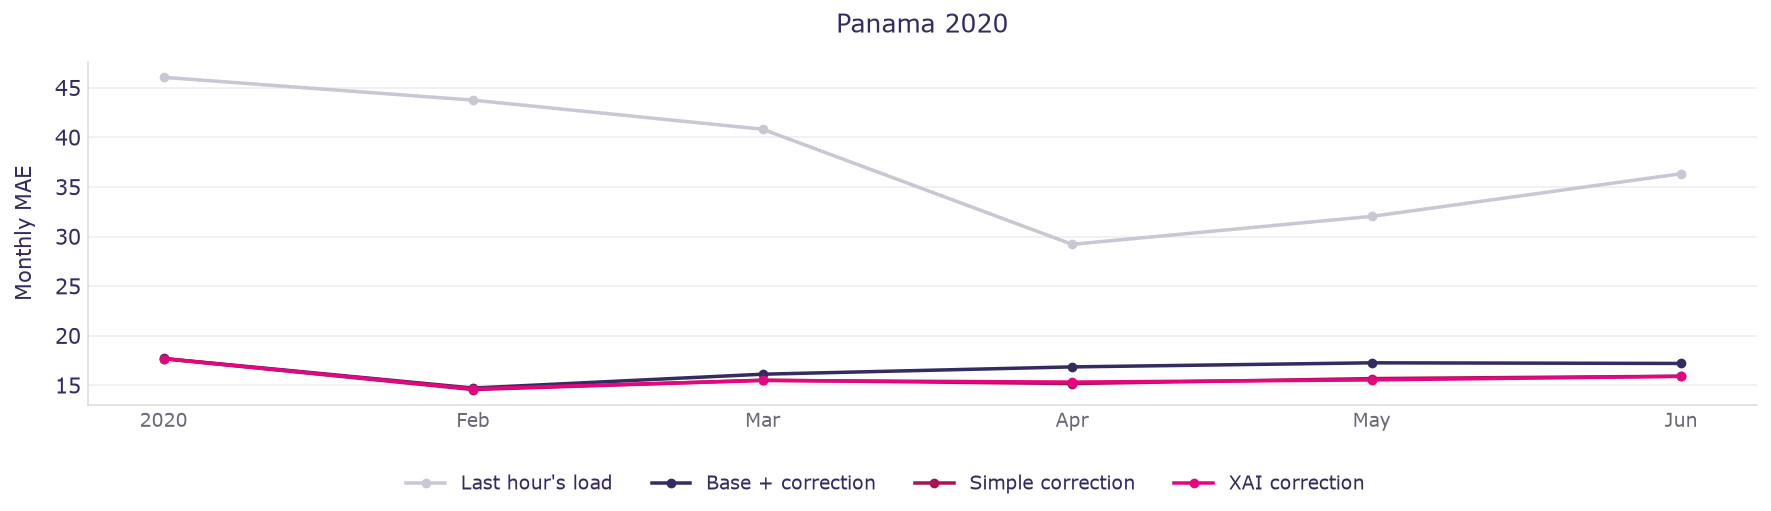

In [11]:
monthly = {}
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(len(DATASETS), 1, figsize=(13, 3.8 * len(DATASETS)), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        frame = runs[dataset]['frame']
        y = frame.target_next_hour.to_numpy()
        monthly[dataset] = pd.DataFrame({
            method: np.abs(runs[dataset]['forecasts'][method] - y)
            for method in METHODS if method != 'base'
        }, index=pd.DatetimeIndex(frame.target_time)).resample('MS').mean()
        ax = axes[row, 0]
        for method in monthly[dataset]:
            ax.plot(monthly[dataset].index, monthly[dataset][method], marker='o', markersize=4,
                    color=PLOT_COLORS[method], label=PLOT_LABELS[method])
        ax.set(title=PLOT_TITLES[dataset], ylabel='Monthly MAE')
        analysis_dates(ax, maxticks=8)
        analysis_grid(ax, 'y')
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=4)
    fig.tight_layout(pad=1.8, h_pad=3, rect=(0, 0.07, 1, 1))
    plt.show()


## 9. Rapid load changes

Rapid-increase and rapid-decrease thresholds were fixed before development.
The observed change determines evaluation scope only, not a model input.
`n` is the number of evaluated hours in each scope.


In [12]:
scope_view = metrics[
    metrics.scope.ne("overall") & metrics.method.isin(("residual", "hourly_bias", "credit_feedback"))
].assign(Dataset=lambda x: x.dataset.map(COUNTRIES),
         Method=lambda x: x.method.map(LABELS))
display(scope_view[["Dataset", "scope", "Method", "n", "MAE", "RMSE"]].rename(
    columns={"scope": "Scope", "n": "Hours"}
))

,Dataset,Scope,Method,Hours,MAE,RMSE
7,Panama,rapid_increase,Base + correction,72,23.6682,33.2959
8,Panama,rapid_decrease,Base + correction,137,26.7330,34.5542
10,Panama,rapid_increase,Simple correction,72,23.1300,32.8417
11,Panama,rapid_decrease,Simple correction,137,26.7858,34.5369
22,Panama,rapid_increase,XAI correction,72,23.2331,32.5053
23,Panama,rapid_decrease,XAI correction,137,26.2101,34.2528


## 10. Where does the XAI benefit come from?

Controls share the residual model and selected XAI settings. Change one mechanism at a
time: weight the whole correction, omit interaction credit, or remove hour grouping.
The separately tuned standalone-credit variant also has its own development settings.
These comparisons help distinguish component-level effects.


In [13]:
controls = ("residual", "scalar_adaptive", "standalone_feedback", "credit_feedback",
            "matched_scalar", "matched_standalone", "no_context")
display(overall[overall.method.isin(controls)].assign(
    Dataset=lambda x: x.dataset.map(COUNTRIES), Method=lambda x: x.method.map(LABELS)
)[["Dataset", "Method", "n", "MAE", "RMSE", "improvement_vs_residual_pct"]])

,Dataset,Method,n,MAE,RMSE,improvement_vs_residual_pct
6,Panama,Base + correction,4273,16.6506,22.2651,0.0000
15,Panama,Adaptive weight,4273,16.6227,22.2090,0.1678
18,Panama,Separate credit,4273,15.7654,21.2128,5.3165
21,Panama,XAI correction,4273,15.7765,21.2161,5.2498
24,Panama,Single weight,4273,16.6476,22.2568,0.0178
27,Panama,No interaction credit,4273,15.7654,21.2128,5.3165
30,Panama,No hour grouping,4273,16.5531,22.1523,0.5856


## 11. Credit, memory and setting sensitivity

The primary rule uses squared-error credit; the MAE variant uses absolute-error credit.
Decaying memory emphasises recent outcomes. Nine predeclared window/strength
combinations describe setting sensitivity without selecting a new final method.
The heatmap shows percentage MAE gain over the unweighted residual forecast.


In [14]:
robust_methods = ("residual", "credit_feedback", "mae_credit", "recency_credit")
display(overall[overall.method.isin(robust_methods)][
    ["dataset", "method", "n", "MAE", "RMSE", "improvement_vs_residual_pct",
     "harmful_rate_vs_base", "harmful_magnitude_vs_base"]
])

,dataset,method,n,MAE,RMSE,improvement_vs_residual_pct,harmful_rate_vs_base,harmful_magnitude_vs_base
6,panama,residual,4273,16.6506,22.2651,0.0000,0.3721,2.2034
21,panama,credit_feedback,4273,15.7765,21.2161,5.2498,0.3400,1.9728
33,panama,mae_credit,4273,15.8054,21.2752,5.0763,0.3436,1.9815
36,panama,recency_credit,4273,15.7790,21.2131,5.2347,0.3405,1.9801


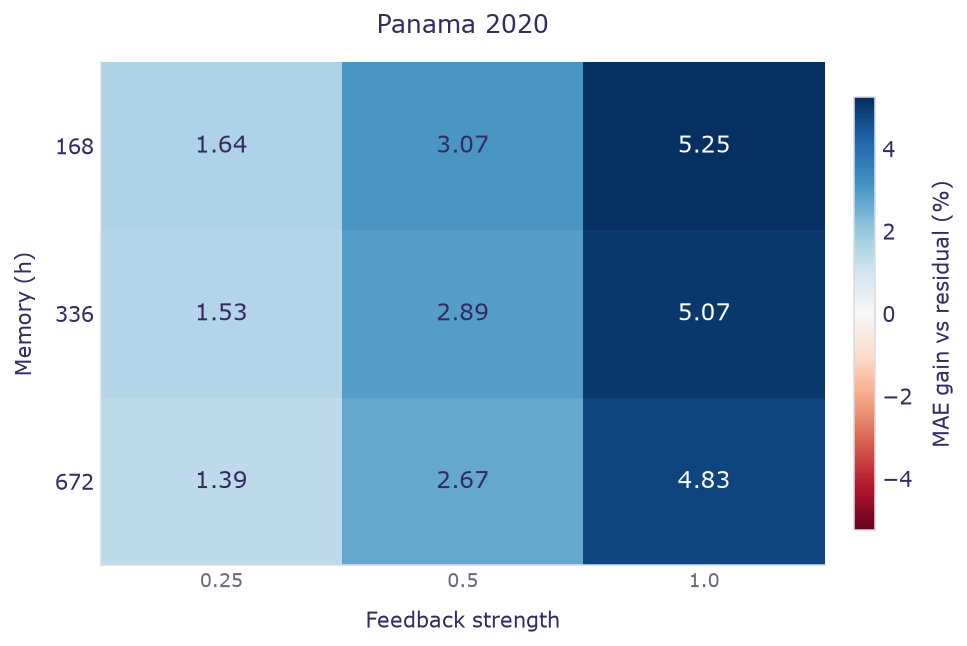

In [15]:
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.8 * len(DATASETS), 4.5), squeeze=False, layout='constrained')
    grids = {}
    for dataset in DATASETS:
        values = overall[overall.dataset.eq(dataset) & overall.method.str.startswith('sensitivity_')].copy()
        values['window'] = values.method.str.extract(r'_w(\d+)', expand=False).astype(int)
        values['strength'] = values.method.str.extract(r'_s([\d.]+)', expand=False).astype(float)
        grids[dataset] = values.pivot(index='window', columns='strength', values='improvement_vs_residual_pct')
    limit = max(abs(grid.to_numpy()).max() for grid in grids.values())
    limit = max(float(limit), 1e-9)
    for col, dataset in enumerate(DATASETS):
        grid = grids[dataset]
        ax = axes[0, col]
        picture = ax.imshow(grid.to_numpy(), cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
        ax.set_xticks(range(len(grid.columns)), grid.columns)
        ax.set_yticks(range(len(grid.index)), grid.index)
        for row in range(len(grid.index)):
            for column in range(len(grid.columns)):
                value = float(grid.iloc[row, column])
                ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=12,
                        color='white' if abs(value) > 0.65 * limit else TALTECH_COLORS["ink"])
        ax.set(title=PLOT_TITLES[dataset], xlabel='Feedback strength', ylabel='Memory (h)')
    fig.colorbar(picture, ax=list(axes.flat), label='MAE gain vs residual (%)', shrink=0.86, pad=0.04)
    plt.show()


## 12. Simple versus XAI correction

The difference is **absolute error of simple correction − absolute error of XAI**.
Negative values favour simple correction; positive values favour XAI.

Resample complete time blocks to retain short-range dependence. Bonferroni adjustment
covers the three Panama scopes: all hours, rapid increases and rapid decreases.
An interval containing zero indicates no clear difference, not equivalence.
These retrospective intervals do not remove the effects of earlier development choices.


In [16]:
interval_rows = []
comparison_count = len(DATASETS) * 3
for dataset in DATASETS:
    run = runs[dataset]
    frame, forecasts = run["frame"], run["forecasts"]
    y = frame.target_next_hour.to_numpy()
    delta = abs(forecasts["hourly_bias"] - y) - abs(forecasts["credit_feedback"] - y)
    for scope, mask in scope_masks(frame, run["thresholds"]).items():
        if not mask.any():
            continue
        for block in cfg["evaluation"]["bootstrap_blocks_hours"]:
            interval_rows.append({
                "dataset": dataset, "scope": scope, "n": int(mask.sum()),
                **clock_loss_interval(
                    frame.target_time, delta, mask, block=block,
                    repeats=cfg["evaluation"]["bootstrap_repeats"],
                    seed=cfg["seed"], comparisons=comparison_count,
                ),
            })
intervals = pd.DataFrame(interval_rows)
primary_intervals = intervals[
    intervals.block_hours.eq(cfg["evaluation"]["primary_block_hours"])
].copy()
display(primary_intervals[[
    "dataset", "scope", "n", "difference", "adjusted_low", "adjusted_high"
]])

,dataset,scope,n,difference,adjusted_low,adjusted_high
1,panama,overall,4273,-0.0063,-0.1341,0.1175
3,panama,rapid_increase,72,-0.1032,-1.0125,0.6579
5,panama,rapid_decrease,137,0.5757,-0.1014,1.4465


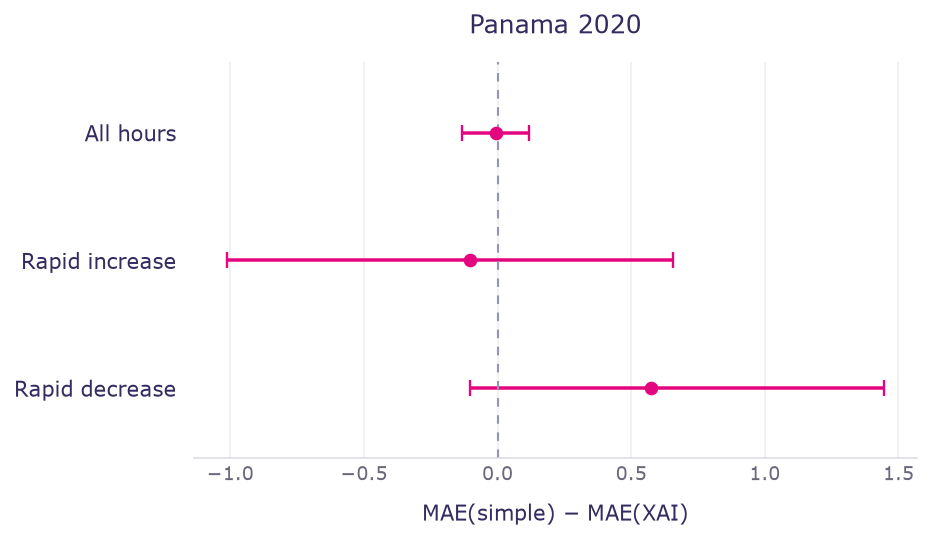

In [17]:
scope_labels = {'overall': 'All hours', 'rapid_increase': 'Rapid increase', 'rapid_decrease': 'Rapid decrease'}
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(7 * len(DATASETS), 4.2), squeeze=False)
    for col, dataset in enumerate(DATASETS):
        values = primary_intervals[primary_intervals.dataset.eq(dataset)]
        ax = axes[0, col]
        analysis_intervals(ax, values, values.scope.map(PLOT_SCOPES), PLOT_COLORS['credit_feedback'])
        ax.set(title=PLOT_TITLES[dataset], xlabel='MAE(simple) − MAE(XAI)')
    fig.tight_layout(pad=1.8, w_pad=4)
    plt.show()


## 13. Harmful corrections

A correction is harmful when its absolute error exceeds the base forecast's error.
Mean added harm includes zero on all other evaluated hours. Lower MAE does not
necessarily imply fewer harmful hours.


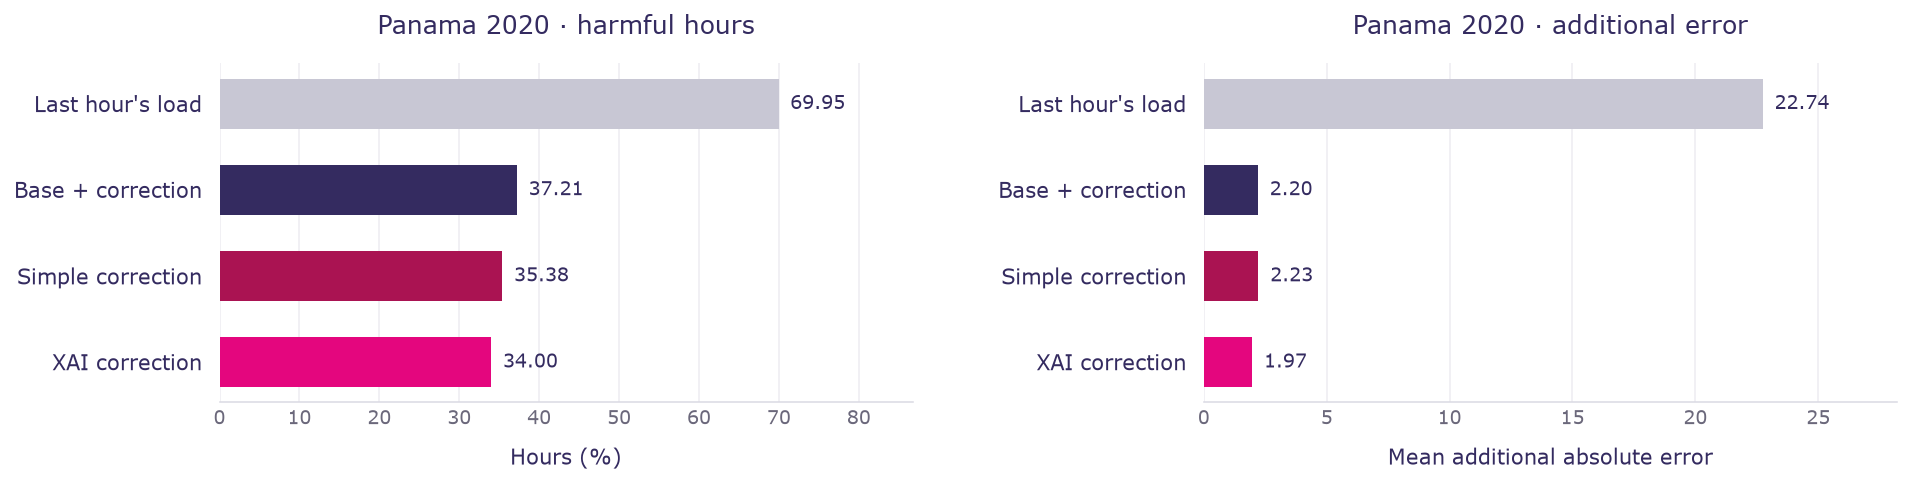

In [18]:
corrections = [m for m in METHODS if m != 'base']
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 3.8 * len(DATASETS)), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        values = overall[overall.dataset.eq(dataset)].set_index('method').loc[corrections]
        for col, (metric, factor, title, label) in enumerate([
            ('harmful_rate_vs_base', 100, 'harmful hours', 'Hours (%)'),
            ('harmful_magnitude_vs_base', 1, 'additional error', 'Mean additional absolute error'),
        ]):
            ax = axes[row, col]
            analysis_barh(ax, [PLOT_LABELS[m] for m in corrections], values[metric] * factor,
                          [PLOT_COLORS[m] for m in corrections])
            ax.set(title=f'{PLOT_TITLES[dataset]} · {title}', xlabel=label)
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=3)
    plt.show()


## 14. Forecasts over time

The example starts at a predeclared offset, independently of the size of any gain.
The right panel shows simple minus XAI absolute error. Positive bars favour XAI;
negative bars favour simple correction.


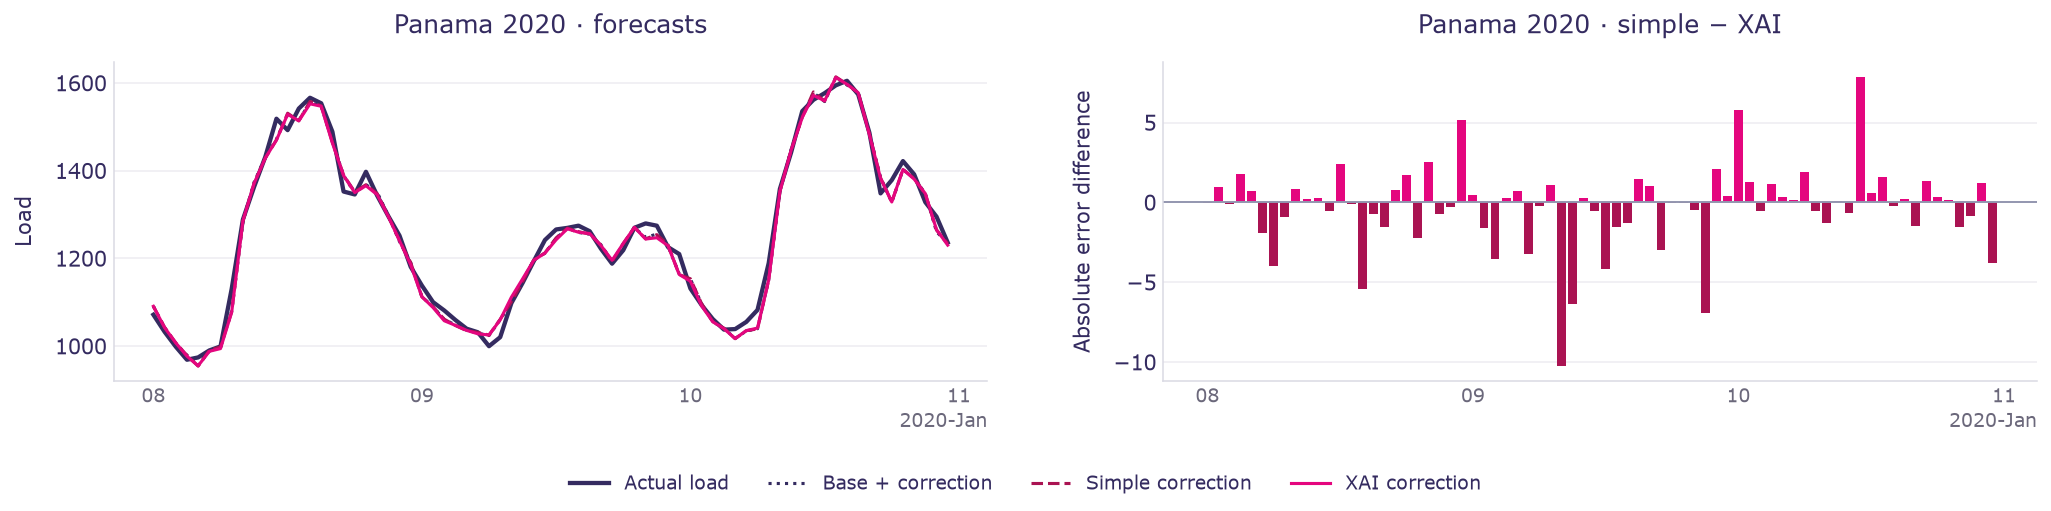

In [19]:
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(15, 3.8 * len(DATASETS)), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        frame, forecasts = runs[dataset]['frame'], runs[dataset]['forecasts']
        start = frame.target_time.min() + pd.Timedelta(days=EXAMPLE_OFFSET_DAYS)
        mask = frame.target_time.ge(start) & frame.target_time.lt(start + pd.Timedelta(days=EXAMPLE_DAYS))
        times = frame.loc[mask, 'target_time']
        y = frame.target_next_hour.to_numpy()
        axes[row, 0].plot(times, y[mask], color=TALTECH_COLORS["ink"], label='Actual load', linewidth=2.2)
        for method, style in [('residual', ':'), ('hourly_bias', '--'), ('credit_feedback', '-')]:
            axes[row, 0].plot(times, forecasts[method][mask], color=PLOT_COLORS[method],
                             label=PLOT_LABELS[method], linestyle=style, linewidth=1.6)
        axes[row, 0].set(title=f'{PLOT_TITLES[dataset]} · forecasts', ylabel='Load')
        delta = abs(forecasts['hourly_bias'] - y) - abs(forecasts['credit_feedback'] - y)
        axes[row, 1].bar(times, delta[mask], width=0.8 / 24,
            color=np.where(delta[mask] >= 0, PLOT_COLORS['credit_feedback'], PLOT_COLORS['hourly_bias']))
        axes[row, 1].axhline(0, color=TALTECH_COLORS["line"], linewidth=1)
        axes[row, 1].set(title=f'{PLOT_TITLES[dataset]} · simple − XAI', ylabel='Absolute error difference')
        for ax in axes[row]:
            analysis_dates(ax)
            analysis_grid(ax, 'y')
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=4)
    fig.tight_layout(pad=1.8, h_pad=3, w_pad=3, rect=(0, 0.07, 1, 1))
    plt.show()


## 15. Explanation-component weights

A weight of **1** retains the component; **0** removes it. Mean weight is not feature
importance or a physical cause. Opposite-signed components can cancel each other.


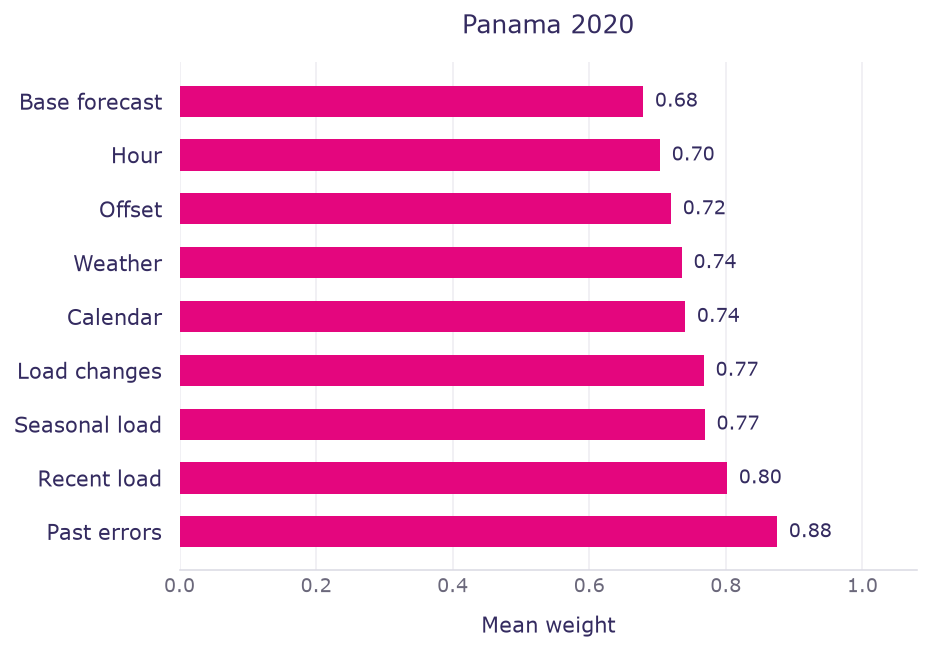

In [20]:
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(7 * len(DATASETS), 5), squeeze=False)
    for col, dataset in enumerate(DATASETS):
        average_weights = runs[dataset]['weights'].mean().sort_values()
        ax = axes[0, col]
        analysis_barh(ax, [PLOT_GROUPS.get(name, name) for name in average_weights.index],
                      average_weights, PLOT_COLORS['credit_feedback'])
        ax.set(xlim=(0, 1.08), title=PLOT_TITLES[dataset], xlabel='Mean weight')
    fig.tight_layout(pad=1.8, w_pad=4)
    plt.show()


## 16. Compare three explanation methods

| Method | Operation |
|---|---|
| TreeSHAP | Computes feature contributions from the fitted tree model. |
| LIME | Fits a local linear approximation around each input. |
| Group ablation | Replaces one input group with training-background values and averages the prediction changes. |

Method references: [TreeSHAP](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html),
[LIME](https://github.com/marcotcr/lime),
[feature ablation](https://captum.ai/api/feature_ablation.html).

All methods share the **trained residual model, evaluation rows, feature groups and
credit-based weighting rule**. No new forecasting model is trained. Aggregate TreeSHAP
and LIME feature contributions into the same groups. LIME uses all features; a continuous
feature's contribution is its coefficient times its scaled input. Ablation replaces a
group jointly using the same training-background row.

**Unexplained remainder:** `model output − intercept − sum of contributions`.
TreeSHAP reconstructs the model output up to numerical error. LIME and ablation may not.
Keep their remainder unchanged and weight only contributions and the intercept.
Without weighting, all methods must reconstruct the same ordinary residual forecast.

If $g_t=\sum_j c_{jt}+u_t$, the final forecast is
$b_t+u_t+\sum_j w_{jt}c_{jt}$, where $b_t$ is the base forecast, $c_{jt}$ includes
the intercept, $u_t$ is the unchanged remainder and weights lie in $[0,1]$.
Credit uses the base forecast plus the unchanged remainder as its reference.

Report the remainder before adding it back. Exact reconstruction afterwards validates
the combination rule, not explanation accuracy. Ablation interactions can be omitted or
counted in multiple contributions. The intercept is weighted but is not a physical input.

Background samples, LIME scales and categorical frequencies use training data only.
Binary features are categorical in LIME; independent perturbations of other inputs
can create unusual combinations. TreeSHAP, LIME and ablation define intercepts differently.

Sample sizes and seeds are fixed. Shared correction settings were selected with
TreeSHAP and are not retuned for each explainer. Conclusions therefore concern these
explainer/combination-rule configurations, not a universally best explanation method
or human interpretability.


In [21]:
xai_runs, xai_metric_parts, xai_time_parts, xai_check_parts = {}, [], [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        run = runs[dataset]
        print(COUNTRIES[dataset], "- three explanation methods", flush=True)
        compared = compare_explainers(
            run["residual_model"], run["training"], run["frame"], run["inputs"],
            choices["credit_feedback"]["setting"], choices["hourly_bias"]["setting"], cfg["feedback"],
            options=XAI_OPTIONS, seed=cfg["seed"], progress=True,
        )
        np.testing.assert_allclose(compared["forecasts"]["tree_shap"],
                                   run["forecasts"]["credit_feedback"], rtol=1e-10, atol=1e-8)
        np.testing.assert_allclose(compared["forecasts"]["hourly_bias"],
                                   run["forecasts"]["hourly_bias"], rtol=1e-10, atol=1e-8)
        assert compared["background_last_target"] <= run["frame"].origin_time.min()
        xai_runs[dataset] = compared
        xai_metric_parts.append(score_forecasts(
            run["frame"], compared["forecasts"], run["thresholds"], cfg, "final"
        ).assign(dataset=dataset))
        xai_time_parts.append(compared["timing"].assign(dataset=dataset))
        xai_check_parts.append(compared["checks"].assign(dataset=dataset))
        print("Evaluated hours:", len(run["frame"]), "| ablation background rows:",
              len(compared["background"]), "| last background target:", compared["background_last_target"])

xai_metrics = pd.concat(xai_metric_parts, ignore_index=True)
xai_timing = pd.concat(xai_time_parts, ignore_index=True)
xai_checks = pd.concat(xai_check_parts, ignore_index=True)
xai_overall = xai_metrics[xai_metrics.scope.eq("overall") & xai_metrics.method.ne("base")].copy()
print("Shared correction settings:", choices["credit_feedback"]["setting"])
quality_view = xai_checks.assign(Dataset=lambda x: x.dataset.map(COUNTRIES),
                                 Method=lambda x: x.method.map(XAI_LABELS))
display(quality_view[["Dataset", "Method", "n", "native_gap_mae", "native_gap_max_abs",
                      "lime_local_r2_mean", "lime_local_r2_min"]].rename(columns={
    "n": "Hours", "native_gap_mae": "Mean absolute unexplained remainder", "native_gap_max_abs": "Maximum absolute remainder",
    "lime_local_r2_mean": "Mean LIME local R²", "lime_local_r2_min": "Minimum LIME local R²",
}))
display(quality_view[["Dataset", "Method", "reconstruction_max_abs"]].assign(
    reconstruction_max_abs=lambda x: x.reconstruction_max_abs.map("{:.2e}".format)
).rename(columns={"reconstruction_max_abs": "Maximum reconstruction error after adding remainder"}))
print("LIME R² describes local fit on perturbed inputs, not load-forecast accuracy.")


Panama - three explanation methods


  tree_shap: 4273 rows


  tree_shap: done in 3.77s


  lime: 4273 rows


  LIME 512/4273


  LIME 1024/4273


... (10 outputs left out)

Evaluated hours: 4273 | ablation background rows: 32 | last background target: 2019-12-29 07:00:00
Shared correction settings: {'window_hours': 168, 'by_hour': True, 'strength': 1.0}


,Dataset,Method,Hours,Mean absolute unexplained remainder,Maximum absolute remainder,Mean LIME local R²,Minimum LIME local R²
0,Panama,TreeSHAP,4273,0.0000,0.0000,NaN,NaN
1,Panama,LIME,4273,7.2113,46.0802,0.5742,0.3194
2,Panama,Group ablation,4273,6.0111,61.8276,NaN,NaN


,Dataset,Method,Maximum reconstruction error after adding remainder
0,Panama,TreeSHAP,0.00e+00
1,Panama,LIME,3.55e-15
2,Panama,Group ablation,3.55e-15


LIME R² describes local fit on perturbed inputs, not load-forecast accuracy.


## 17. Accuracy and added computation time

Added time includes explainer preparation, model queries, remainder calculation,
checks and adaptive weighting. Shared model training and initial forecasts are excluded.
The simple method is timed for its additional correction only.

The time panel uses a linear scale for total added seconds over the evaluation batch.
Average milliseconds per forecast are batch averages, not measured live latency.
Accuracy uses all common evaluation hours. MAE gain is relative to residual correction;
harmful-hour rates are relative to the base forecast. Bias is prediction minus observation.


,Dataset,Method,Hours,MAE,RMSE,Bias,MAE gain (%),Harmful hours (%),Added time (s),Average added time (ms/forecast)
0,Panama,Base + correction,4273,16.6506,22.2651,0.9595,0.0000,37.2104,NaN,NaN
1,Panama,Simple correction,4273,15.7702,21.1909,0.7312,5.2875,35.3850,0.0673,0.0157
2,Panama,TreeSHAP,4273,15.7765,21.2161,0.2676,5.2498,34.0042,3.7739,0.8832
3,Panama,LIME,4273,15.9569,21.4219,-0.0668,4.1661,37.9593,54.5568,12.7678
4,Panama,Group ablation,4273,15.8016,21.2928,0.3252,5.0990,36.3211,7.9830,1.8682


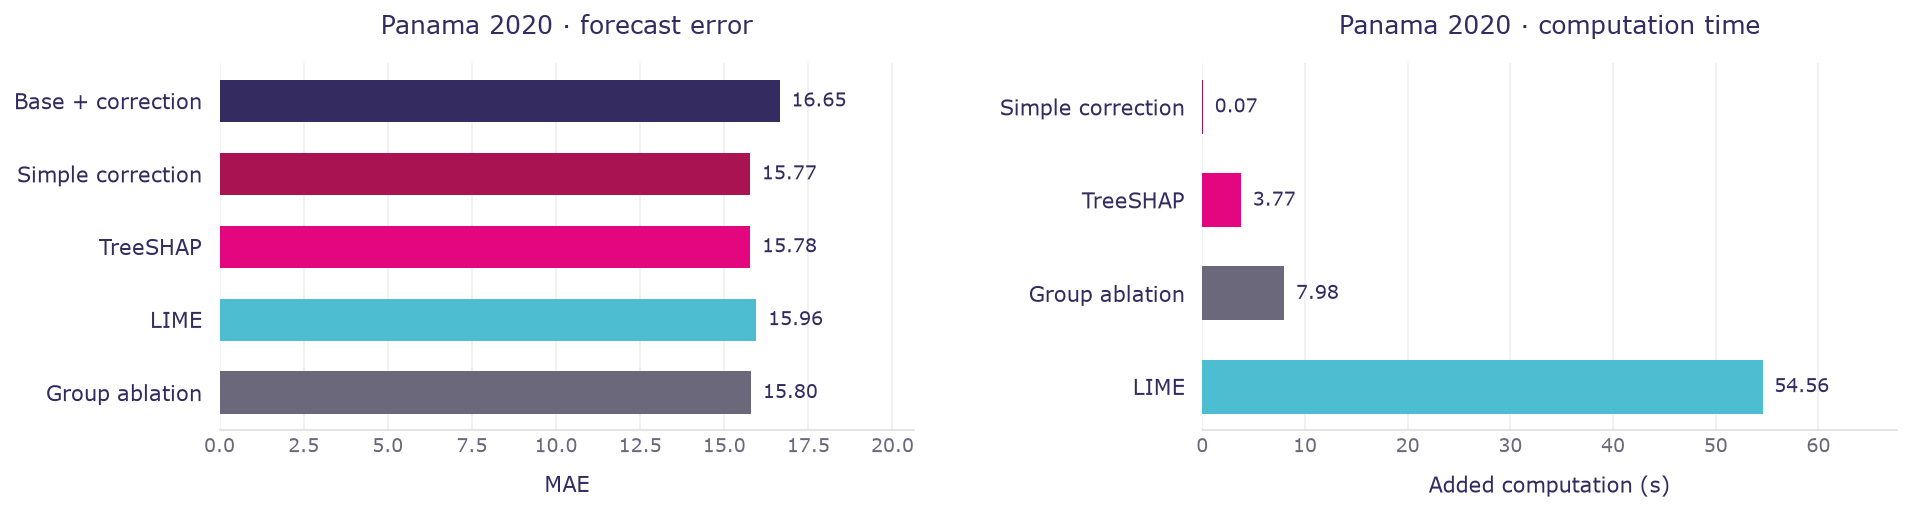

In [22]:
xai_view = xai_overall.merge(
    xai_timing[["dataset", "method", "total_seconds", "ms_per_forecast"]],
    on=["dataset", "method"], how="left",
).assign(Dataset=lambda x: x.dataset.map(COUNTRIES), Method=lambda x: x.method.map(XAI_LABELS))
xai_view["Harmful hours (%)"] = 100 * xai_view.harmful_rate_vs_base
display(xai_view[["Dataset", "Method", "n", "MAE", "RMSE", "bias",
                  "improvement_vs_residual_pct", "Harmful hours (%)",
                  "total_seconds", "ms_per_forecast"]].rename(columns={
    "n": "Hours", "bias": "Bias", "improvement_vs_residual_pct": "MAE gain (%)",
    "total_seconds": "Added time (s)", "ms_per_forecast": "Average added time (ms/forecast)",
}))
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 4 * len(DATASETS)), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        values = xai_overall[xai_overall.dataset.eq(dataset)]
        analysis_barh(axes[row, 0], [PLOT_LABELS[m] for m in values.method], values.MAE,
                      [PLOT_COLORS[m] for m in values.method])
        axes[row, 0].set(title=f'{PLOT_TITLES[dataset]} · forecast error', xlabel='MAE')
        times = xai_timing[xai_timing.dataset.eq(dataset)].set_index('method')
        order = ['hourly_bias', 'tree_shap', 'feature_ablation', 'lime']
        times = times.loc[order]
        analysis_barh(axes[row, 1], [PLOT_LABELS[m] for m in order], times.total_seconds,
                      [PLOT_COLORS[m] for m in order])
        axes[row, 1].set(title=f'{PLOT_TITLES[dataset]} · computation time', xlabel='Added computation (s)')
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=3)
    plt.show()


## 18. Do explanation methods differ?

Compare the three explainers pairwise and each against simple correction.
**Difference = absolute error of A − absolute error of B**; negative favours A.

Six method pairs and three Panama scopes give **18 adjusted comparisons**.
Use 168-hour blocks for the primary analysis and 24-hour blocks for sensitivity.
The table shows overall results; the plot compares LIME and ablation with TreeSHAP
in each scope. Intervals are approximate and retrospective. Crossing zero does not
establish equivalence.


In [23]:
xai_interval_rows = []
xai_comparison_count = len(DATASETS) * len(XAI_PAIRS) * 3
for dataset in DATASETS:
    run = runs[dataset]
    frame = run["frame"]
    forecasts = xai_runs[dataset]["forecasts"]
    y = frame.target_next_hour.to_numpy()
    for a, b in XAI_PAIRS:
        difference = abs(forecasts[a] - y) - abs(forecasts[b] - y)
        for scope, mask in scope_masks(frame, run["thresholds"]).items():
            if not mask.any():
                continue
            for block in cfg["evaluation"]["bootstrap_blocks_hours"]:
                xai_interval_rows.append({
                    "dataset": dataset, "A": a, "B": b, "scope": scope, "n": int(mask.sum()),
                    **clock_loss_interval(
                        frame.target_time, difference, mask, block=block,
                        repeats=cfg["evaluation"]["bootstrap_repeats"], seed=cfg["seed"],
                        comparisons=xai_comparison_count,
                    ),
                })
xai_intervals = pd.DataFrame(xai_interval_rows)
xai_primary_intervals = xai_intervals[
    xai_intervals.block_hours.eq(cfg["evaluation"]["primary_block_hours"])
].copy()
display(xai_primary_intervals[xai_primary_intervals.scope.eq("overall")][
    ["dataset", "A", "B", "n", "difference", "adjusted_low", "adjusted_high"]
])
display(xai_metrics[xai_metrics.scope.ne("overall") & xai_metrics.method.isin(XAI_LABELS)][
    ["dataset", "method", "scope", "n", "MAE", "RMSE", "harmful_rate_vs_base"]
])

,dataset,A,B,n,difference,adjusted_low,adjusted_high
1,panama,lime,tree_shap,4273,0.1804,-0.2684,0.6129
7,panama,feature_ablation,tree_shap,4273,0.0251,-0.2598,0.2543
13,panama,feature_ablation,lime,4273,-0.1553,-0.5197,0.2149
19,panama,tree_shap,hourly_bias,4273,0.0063,-0.1472,0.1644
25,panama,lime,hourly_bias,4273,0.1867,-0.3043,0.6448
31,panama,feature_ablation,hourly_bias,4273,0.0314,-0.2852,0.2967


,dataset,method,scope,n,MAE,RMSE,harmful_rate_vs_base
4,panama,residual,rapid_increase,72,23.6682,33.2959,0.4583
5,panama,residual,rapid_decrease,137,26.7330,34.5542,0.6058
7,panama,hourly_bias,rapid_increase,72,23.1300,32.8417,0.4861
8,panama,hourly_bias,rapid_decrease,137,26.7858,34.5369,0.6058
10,panama,tree_shap,rapid_increase,72,23.2331,32.5053,0.4444
11,panama,tree_shap,rapid_decrease,137,26.2101,34.2528,0.5766
13,panama,lime,rapid_increase,72,23.4772,32.8366,0.4861
14,panama,lime,rapid_decrease,137,27.1749,35.3195,0.5693
16,panama,feature_ablation,rapid_increase,72,23.3834,32.2419,0.4444
17,panama,feature_ablation,rapid_decrease,137,26.5918,34.7731,0.5255


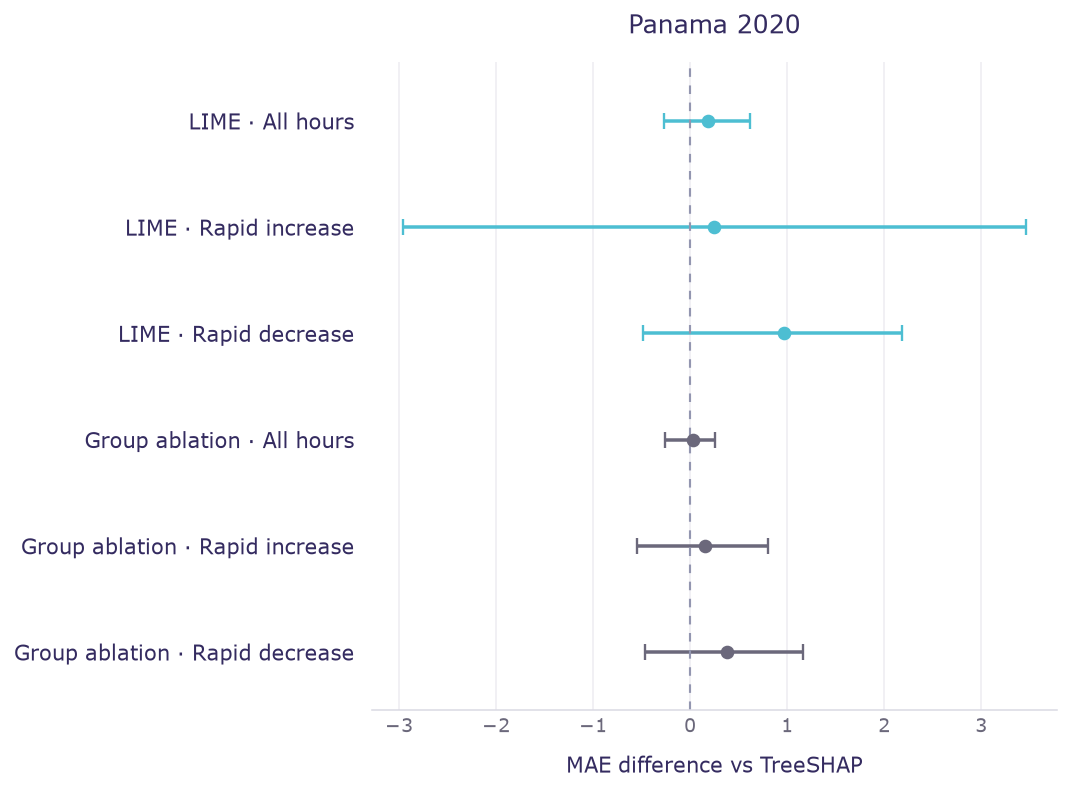

In [24]:
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(8 * len(DATASETS), 6), squeeze=False)
    for col, dataset in enumerate(DATASETS):
        values = xai_primary_intervals[
            xai_primary_intervals.dataset.eq(dataset) & xai_primary_intervals.B.eq('tree_shap')]
        labels = [f'{PLOT_LABELS[a]} · {PLOT_SCOPES[s]}' for a, s in zip(values.A, values.scope)]
        ax = axes[0, col]
        analysis_intervals(ax, values, labels, [PLOT_COLORS[m] for m in values.A])
        ax.set(title=PLOT_TITLES[dataset], xlabel='MAE difference vs TreeSHAP')
    fig.tight_layout(pad=1.8, w_pad=4)
    plt.show()


## 19. Runtime repeats and explanation stability

Repeat timings on the same rows spread across the evaluation period. Preparation cost
is included, so subset time need not scale linearly to the full batch.

Change only the random seed for stability checks. LIME perturbations and the ablation
background change; TreeSHAP is a deterministic reference. Measure contribution and
remainder changes. The primary seed must reproduce the corresponding full-batch rows.
This measures explanation sensitivity, not complete adaptive-forecast stability,
and does not select a new method.


In [25]:
timing_repeats, stability_rows = [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        run, compared = runs[dataset], xai_runs[dataset]
        count = min(XAI_OPTIONS["benchmark_rows"], len(run["frame"]))
        positions = np.linspace(0, len(run["frame"]) - 1, count, dtype=int)
        sample = run["frame"][run["inputs"]].iloc[positions]
        for method in EXPLAINERS:
            for repeat in range(XAI_OPTIONS["timing_repeats"]):
                _, _, info = explain_components(
                    run["residual_model"], sample, method, run["training"],
                    options=XAI_OPTIONS, seed=cfg["seed"],
                )
                timing_repeats.append({"dataset": dataset, "method": method, "repeat": repeat + 1,
                                      "n": count, "seconds": info["explanation_seconds"]})
            reference = compared["components"][method].iloc[positions]
            fixed_reference = compared["remainders"][method].iloc[positions]
            for seed in XAI_OPTIONS["stability_seeds"]:
                components, remainder, info = explain_components(
                    run["residual_model"], sample, method, run["training"], options=XAI_OPTIONS, seed=seed
                )
                difference = np.abs(components.to_numpy() - reference.to_numpy())
                stability_rows.append({"dataset": dataset, "method": method, "seed": seed, "n": count,
                                       "mean_abs_component_change": float(difference.mean()),
                                       "max_abs_component_change": float(difference.max()),
                                       "mean_abs_remainder_change": float(abs(remainder - fixed_reference).mean()),
                                       "native_gap_mae": info["native_gap_mae"]})
                if seed == cfg["seed"]:
                    np.testing.assert_allclose(components, reference, atol=1e-8, rtol=1e-9)
                    np.testing.assert_allclose(remainder, fixed_reference, atol=1e-8, rtol=1e-9)
timing_repeats = pd.DataFrame(timing_repeats)
xai_stability = pd.DataFrame(stability_rows)
runtime_summary = timing_repeats.groupby(["dataset", "method"]).agg(
    n=("n", "first"), repeats=("repeat", "count"),
    median_seconds=("seconds", "median"), min_seconds=("seconds", "min"), max_seconds=("seconds", "max"),
).reset_index()
runtime_summary["median_ms_per_forecast"] = 1000 * runtime_summary.median_seconds / runtime_summary.n
display(runtime_summary.assign(dataset=lambda x: x.dataset.map(COUNTRIES),
                               method=lambda x: x.method.map(XAI_LABELS)).rename(columns={
    "dataset": "Dataset", "method": "Method", "n": "Hours", "repeats": "Repeats",
    "median_seconds": "Median time (s)", "min_seconds": "Minimum time (s)", "max_seconds": "Maximum time (s)",
    "median_ms_per_forecast": "Median time (ms/forecast)",
}))
display(xai_stability.assign(dataset=lambda x: x.dataset.map(COUNTRIES),
                             method=lambda x: x.method.map(XAI_LABELS)).rename(columns={
    "dataset": "Dataset", "method": "Method", "seed": "Seed", "n": "Hours",
    "mean_abs_component_change": "Mean absolute contribution change", "max_abs_component_change": "Maximum absolute contribution change",
    "mean_abs_remainder_change": "Mean absolute remainder change", "native_gap_mae": "Mean absolute unexplained remainder",
}))
from importlib.metadata import version
print("Environment: Python", sys.version.split()[0], "| SHAP", version("shap"), "| LIME", version("lime"),
      "| thread limit", cfg["workers"])
print("Ablation background rows:", XAI_OPTIONS["background_size"], "| LIME samples:", XAI_OPTIONS["lime_samples"],
      "| primary seed:", cfg["seed"])


,Dataset,Method,Hours,Repeats,Median time (s),Minimum time (s),Maximum time (s),Median time (ms/forecast)
0,Panama,Group ablation,64,3,0.2304,0.2155,0.2315,3.5996
1,Panama,LIME,64,3,1.7087,1.3492,1.7474,26.6985
2,Panama,TreeSHAP,64,3,0.1986,0.1621,0.2698,3.1031


,Dataset,Method,Seed,Hours,Mean absolute contribution change,Maximum absolute contribution change,Mean absolute remainder change,Mean absolute unexplained remainder
0,Panama,TreeSHAP,42,64,0.0000,0.0000,0.0000,0.0000
1,Panama,TreeSHAP,43,64,0.0000,0.0000,0.0000,0.0000
2,Panama,TreeSHAP,44,64,0.0000,0.0000,0.0000,0.0000
3,Panama,LIME,42,64,0.0000,0.0000,0.0000,7.7573
4,Panama,LIME,43,64,1.6102,13.3859,1.1736,7.5128
5,Panama,LIME,44,64,1.5038,18.0328,0.9723,7.7320
6,Panama,Group ablation,42,64,0.0000,0.0000,0.0000,5.8875
7,Panama,Group ablation,43,64,1.1811,4.8712,2.6043,5.7494
8,Panama,Group ablation,44,64,1.4065,6.1710,3.7276,7.0661


Environment: Python 3.11.2 | SHAP 0.51.0 | LIME 0.2.0.1 | thread limit 2
Ablation background rows: 32 | LIME samples: 512 | primary seed: 42


## 20. Apply combined correction on Panama 2020

Reuse the base and residual models, components, thresholds and evaluation rows from
the primary Panama run. No additional model fitting or evaluation year is introduced.
Apply the recorded XAI and bias settings, using each first-stage forecast's own earlier
errors for its second layer. This is a retrospective extension on the same evaluation
period, not a new confirmation dataset.


In [26]:
combined_dataset = combined_protocol["dataset"]
combined_year = combined_protocol["test_year"]
combined_run = runs[combined_dataset]
combined_frame = combined_run["frame"]
combined_components = combined_run["components"]
combined_thresholds = combined_run["thresholds"]
with threadpool_limits(limits=cfg["workers"]):
    combined_predictions = combined_forecasts(
        combined_frame, combined_components, combined_protocol["xai_setting"],
        combined_protocol["bias_setting"], combined_protocol["feedback"],
    )
combined_predictions["naive"] = persistence_forecast(combined_frame)
for method in ("base", "residual", "hourly_bias", "credit_feedback", "matched_scalar", "naive"):
    np.testing.assert_allclose(combined_predictions[method], combined_run["forecasts"][method], atol=1e-8)
assert set(combined_frame.target_time.dt.year) == {combined_year}
assert combined_protocol == combined_protocol_snapshot
combined_metrics = score_forecasts(
    combined_frame, combined_predictions, combined_thresholds, cfg, "combined"
)
display(pd.DataFrame([{
    "Dataset": COUNTRIES[combined_dataset], "Year": combined_year,
    "First target": combined_frame.target_time.min(),
    "Last target": combined_frame.target_time.max(), "Evaluated hours": len(combined_frame),
    "Feedback warm-up (h)": combined_protocol["feedback"]["warmup_hours"],
    "Evaluation status": "Retrospective; same rows and models as the primary comparison",
}]))


,Dataset,Year,First target,Last target,Evaluated hours,Feedback warm-up (h),Evaluation status
0,Panama,2020,2020-01-01,2020-06-27,4273,72,Retrospective; same rows and models as the pri...


## 21. Combined correction: overall and monthly accuracy

Both XAI and its single-weight control receive the same bias layer, each using its own
past errors. MAE gain and harmful-hour rates here are relative to **simple correction**.
Negative gain means greater error. All methods use identical evaluation hours.
The monthly plot covers only available source months and does not drive retuning.


,Method,Hours,MAE,RMSE,Bias,MAE gain (%),Harmful hours (%)
0,Base forecast,4273,20.4511,27.1860,-0.3301,-29.6819,64.6150
3,Base + correction,4273,16.6506,22.2651,0.9595,-5.5827,59.8877
6,Simple correction,4273,15.7702,21.1909,0.7312,0.0000,0.0000
9,XAI correction,4273,15.7765,21.2161,0.2676,-0.0398,51.1818
12,Single weight,4273,16.6476,22.2568,0.7114,-5.5639,58.6473
15,XAI + simple correction,4273,15.3093,20.6379,0.2074,2.9229,44.3716
18,Single weight + simple correction,4273,15.7940,21.2429,0.5455,-0.1511,26.6323
21,Last hour's load,4273,38.0704,49.2074,0.0166,-141.4075,76.4802


,Method,Scope,n,MAE,RMSE,improvement_vs_simple_pct
1,Base forecast,Rapid increase,72,25.4332,36.9024,-9.9577
2,Base forecast,Rapid decrease,137,26.2070,33.9117,2.1610
4,Base + correction,Rapid increase,72,23.6682,33.2959,-2.3268
5,Base + correction,Rapid decrease,137,26.7330,34.5542,0.1972
7,Simple correction,Rapid increase,72,23.1300,32.8417,0.0000
8,Simple correction,Rapid decrease,137,26.7858,34.5369,0.0000
10,XAI correction,Rapid increase,72,23.2331,32.5053,-0.4460
11,XAI correction,Rapid decrease,137,26.2101,34.2528,2.1494
13,Single weight,Rapid increase,72,23.5310,32.9670,-1.7337
14,Single weight,Rapid decrease,137,26.4428,34.3909,1.2806


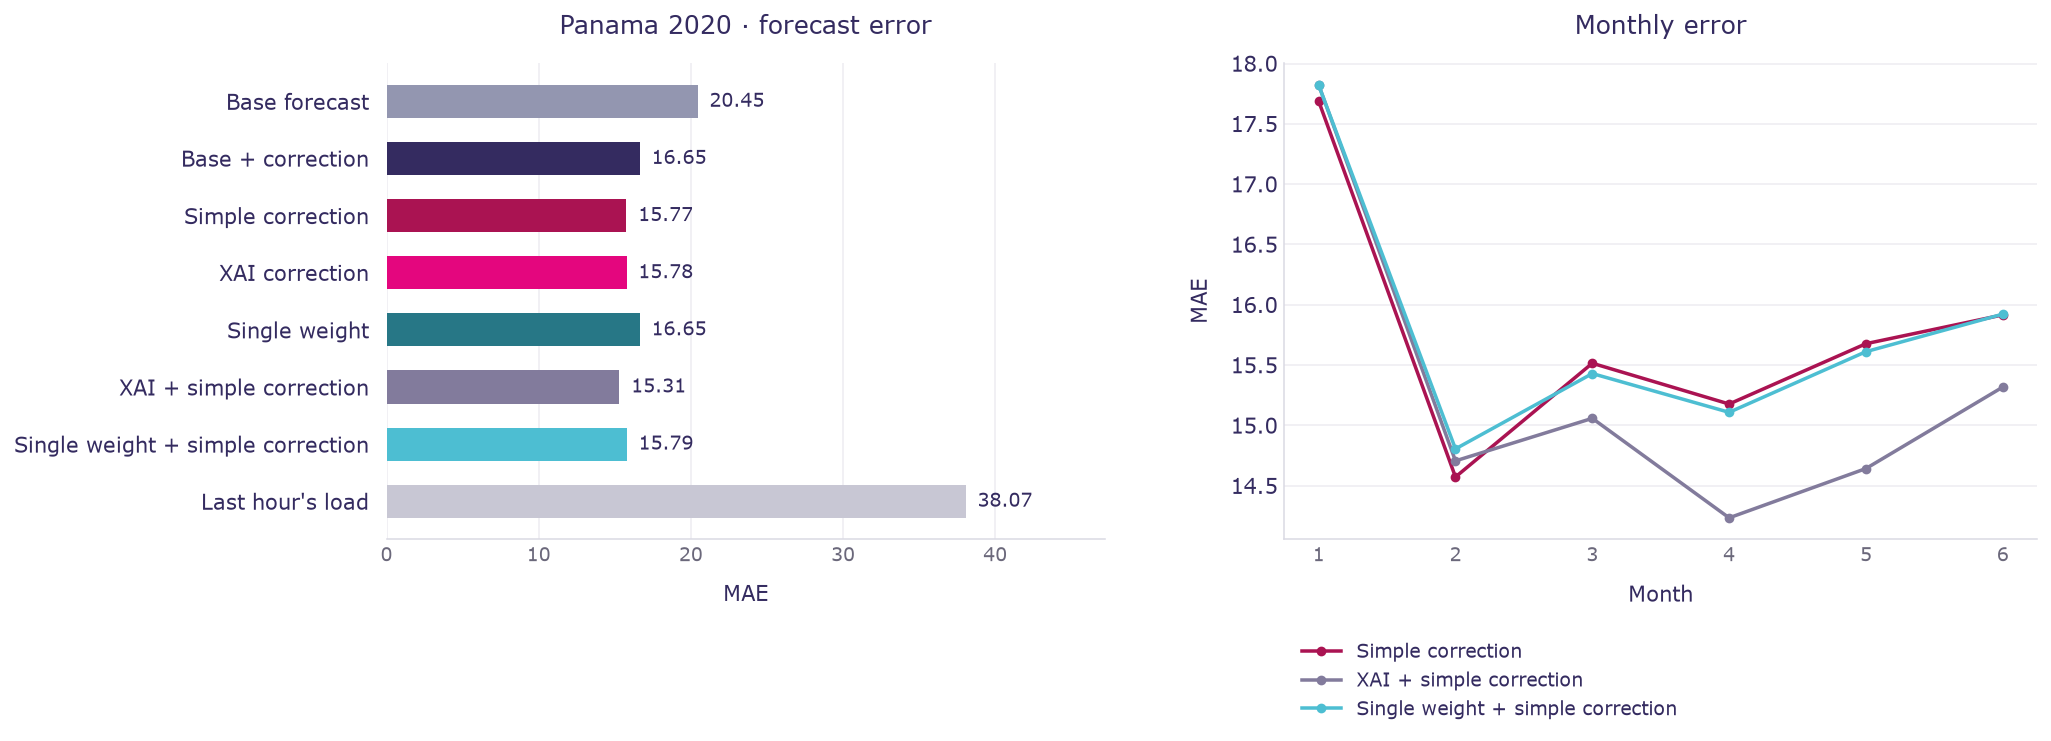

In [27]:
comparison_rows = []
combined_actual = combined_frame.target_next_hour.to_numpy()
for method, predicted in combined_predictions.items():
    difference = abs(predicted - combined_actual) - abs(combined_predictions["hourly_bias"] - combined_actual)
    for scope, mask in scope_masks(combined_frame, combined_thresholds).items():
        if not mask.any():
            continue
        comparison_rows.append({
            "method": method, "scope": scope,
            "improvement_vs_simple_pct": 100 * (1 - abs(predicted[mask] - combined_actual[mask]).mean()
                / abs(combined_predictions["hourly_bias"][mask] - combined_actual[mask]).mean()),
            "harmful_rate_vs_simple_pct": 100 * (difference[mask] > cfg["evaluation"]["harm_tolerance"]).mean(),
        })
combined_metrics = combined_metrics.merge(pd.DataFrame(comparison_rows), on=["method", "scope"])
combined_overall = combined_metrics[combined_metrics.scope.eq("overall")].copy()
display(combined_overall.assign(Method=lambda x: x.method.map(COMBINED_LABELS))[
    ["Method", "n", "MAE", "RMSE", "bias", "improvement_vs_simple_pct", "harmful_rate_vs_simple_pct"]
].rename(columns={"n": "Hours", "bias": "Bias", "improvement_vs_simple_pct": "MAE gain (%)",
                  "harmful_rate_vs_simple_pct": "Harmful hours (%)"}))
display(combined_metrics[combined_metrics.scope.ne("overall")].assign(
    Method=lambda x: x.method.map(COMBINED_LABELS), Scope=lambda x: x.scope.map(scope_labels)
)[["Method", "Scope", "n", "MAE", "RMSE", "improvement_vs_simple_pct"]])
combined_monthly_rows = []
for month, indexes in combined_frame.groupby(combined_frame.target_time.dt.month).groups.items():
    for method in ("hourly_bias", "xai_bias", "scalar_bias"):
        combined_monthly_rows.append({
            "month": month, "method": method,
            "MAE": abs(combined_predictions[method][indexes] - combined_actual[indexes]).mean(),
        })
combined_monthly = pd.DataFrame(combined_monthly_rows)
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={'width_ratios': [1.05, 1.1]})
    analysis_barh(axes[0], [PLOT_LABELS[m] for m in combined_overall.method], combined_overall.MAE,
                  [PLOT_COLORS[m] for m in combined_overall.method])
    axes[0].set(title=f'{PLOT_TITLES[combined_dataset]} · forecast error', xlabel='MAE')
    for method in ('hourly_bias', 'xai_bias', 'scalar_bias'):
        values = combined_monthly[combined_monthly.method.eq(method)]
        axes[1].plot(values.month, values.MAE, marker='o', markersize=4,
                     label=PLOT_LABELS[method].replace('\n', ' '), color=PLOT_COLORS[method])
    axes[1].set(title='Monthly error', xlabel='Month', ylabel='MAE', xticks=sorted(combined_monthly.month.unique()))
    axes[1].legend(loc='upper left', bbox_to_anchor=(0, -0.18), fontsize=10)
    analysis_grid(axes[1], 'y')
    fig.tight_layout(pad=1.8, w_pad=4, rect=(0, 0.05, 1, 1))
    plt.show()


## 22. Does the additional layer help?

**Difference = absolute error of A − absolute error of B**. Intervals below zero
favour A; intervals above zero favour B. Display the 168-hour primary blocks;
24-hour sensitivity results remain in `combined_intervals`.

The first two pairs compare combined XAI with simple correction and with the matched
combined single-weight control. The other pairs isolate the added layer for each
method. Twelve comparisons cover four pairs and three scopes. These intervals do not
make the previously examined Panama evaluation period independent of earlier choices.


,A,B,Scope,Hours,MAE difference,Lower bound,Upper bound
1,XAI + simple correction,Simple correction,All hours,4273,-0.4609,-0.7659,-0.1661
3,XAI + simple correction,Simple correction,Rapid increase,72,-0.3155,-1.0746,0.3378
5,XAI + simple correction,Simple correction,Rapid decrease,137,-0.3513,-1.4636,0.5304
7,XAI + simple correction,Single weight + simple correction,All hours,4273,-0.4848,-0.7552,-0.2085
9,XAI + simple correction,Single weight + simple correction,Rapid increase,72,-0.1733,-0.9983,0.4386
11,XAI + simple correction,Single weight + simple correction,Rapid decrease,137,-0.0544,-0.9663,0.6461
13,XAI + simple correction,XAI correction,All hours,4273,-0.4672,-0.7523,-0.1813
15,XAI + simple correction,XAI correction,Rapid increase,72,-0.4187,-1.7955,0.8611
17,XAI + simple correction,XAI correction,Rapid decrease,137,0.2244,-0.2897,0.6465
19,Single weight + simple correction,Single weight,All hours,4273,-0.8536,-1.2558,-0.4294


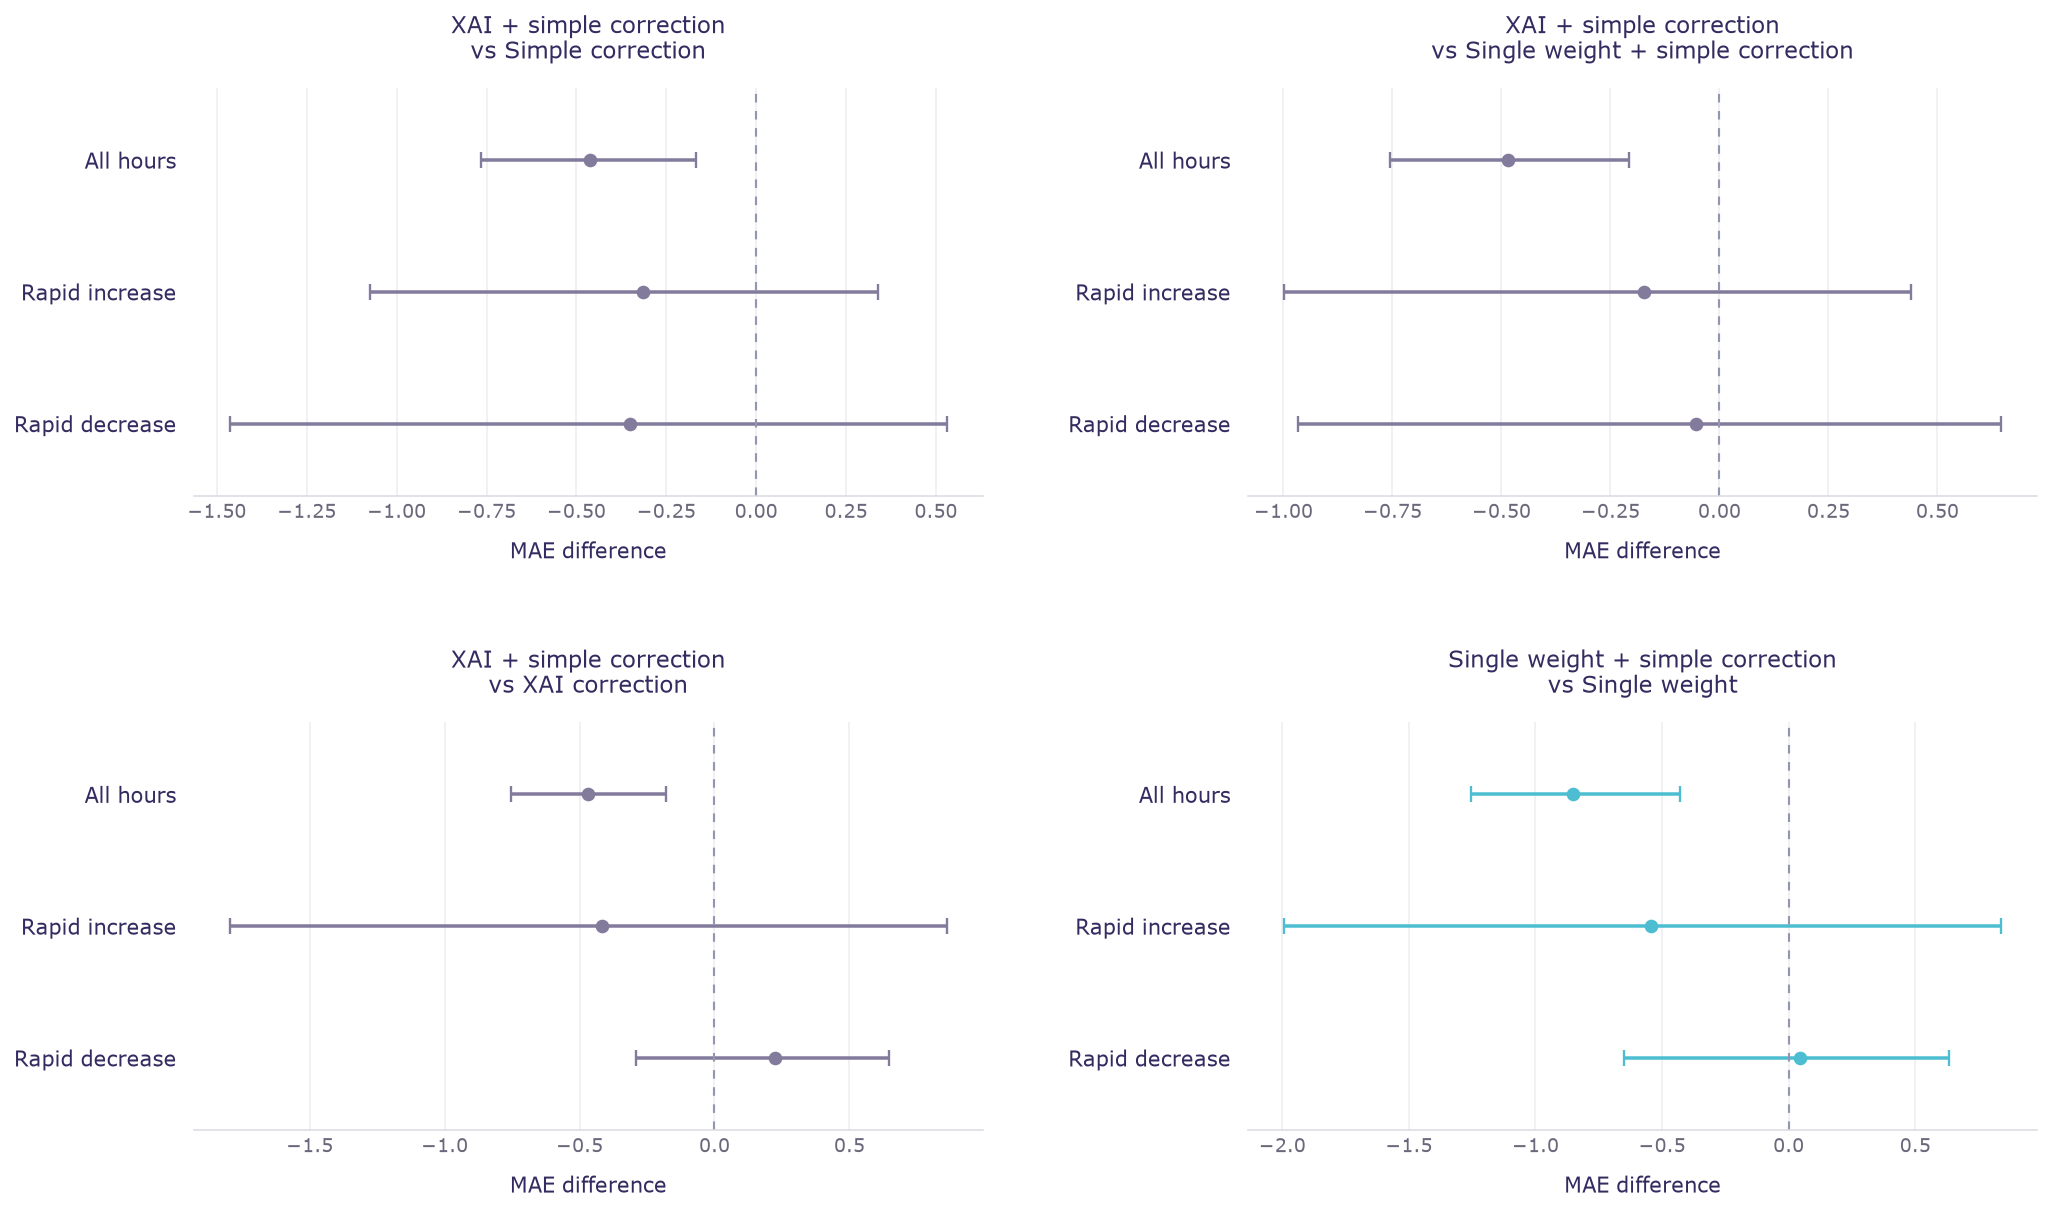

In [28]:
combined_interval_rows = []
combined_comparisons = len(combined_protocol["pairs"]) * 3
for a, b in combined_protocol["pairs"]:
    difference = abs(combined_predictions[a] - combined_actual) - abs(combined_predictions[b] - combined_actual)
    for scope, mask in scope_masks(combined_frame, combined_thresholds).items():
        if not mask.any():
            continue
        for block in combined_protocol["evaluation"]["bootstrap_blocks_hours"]:
            combined_interval_rows.append({
                "A": a, "B": b, "scope": scope, "n": int(mask.sum()),
                **clock_loss_interval(combined_frame.target_time, difference, mask, block=block,
                    repeats=combined_protocol["evaluation"]["bootstrap_repeats"],
                    seed=combined_protocol["seed"], comparisons=combined_comparisons),
            })
combined_intervals = pd.DataFrame(combined_interval_rows)
combined_primary_intervals = combined_intervals[
    combined_intervals.block_hours.eq(combined_protocol["evaluation"]["primary_block_hours"])
].copy()
display(combined_primary_intervals.assign(
    A=lambda x: x.A.map(COMBINED_LABELS), B=lambda x: x.B.map(COMBINED_LABELS),
    scope=lambda x: x.scope.map(scope_labels),
)[["A", "B", "scope", "n", "difference", "adjusted_low", "adjusted_high"]].rename(columns={
    "scope": "Scope", "n": "Hours", "difference": "MAE difference", "adjusted_low": "Lower bound",
    "adjusted_high": "Upper bound",
}))
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, (a, b) in zip(axes.flat, combined_protocol['pairs']):
        values = combined_primary_intervals[
            combined_primary_intervals.A.eq(a) & combined_primary_intervals.B.eq(b)]
        analysis_intervals(ax, values, values.scope.map(PLOT_SCOPES), PLOT_COLORS[a])
        first, second = PLOT_LABELS[a].replace('\n', ' '), PLOT_LABELS[b].replace('\n', ' ')
        ax.set_title(f'{first}\nvs {second}', fontsize=12)
        ax.set_xlabel('MAE difference')
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=4)
    plt.show()

assert combined_protocol == combined_protocol_snapshot
assert choices == selection["choices"]


## 23. Naive forecast benchmark

Predict **next-hour load = the most recently completed load interval** (`load_now`).
No fitting is needed. Evaluate it on the same complete-input rows as all other methods,
although persistence alone could cover additional hours. Positive gain means lower MAE
than persistence. Include combined methods in the same Panama cohort without duplicating
its observations. This is a descriptive benchmark, not independent confirmation.


,Cohort,Method,Hours,MAE,RMSE,MAE gain over persistence (%)
0,Panama 2020,Last hour's load,4273,38.0704,49.2074,0.0000
1,Panama 2020,Base forecast,4273,20.4511,27.1860,46.2809
2,Panama 2020,Base + correction,4273,16.6506,22.2651,56.2637
3,Panama 2020,Simple correction,4273,15.7702,21.1909,58.5763
4,Panama 2020,XAI correction,4273,15.7765,21.2161,58.5598
5,Panama 2020,Single weight,4273,16.6476,22.2568,56.2715
6,Panama 2020,XAI + simple correction,4273,15.3093,20.6379,59.7870
7,Panama 2020,Single weight + simple correction,4273,15.7940,21.2429,58.5137


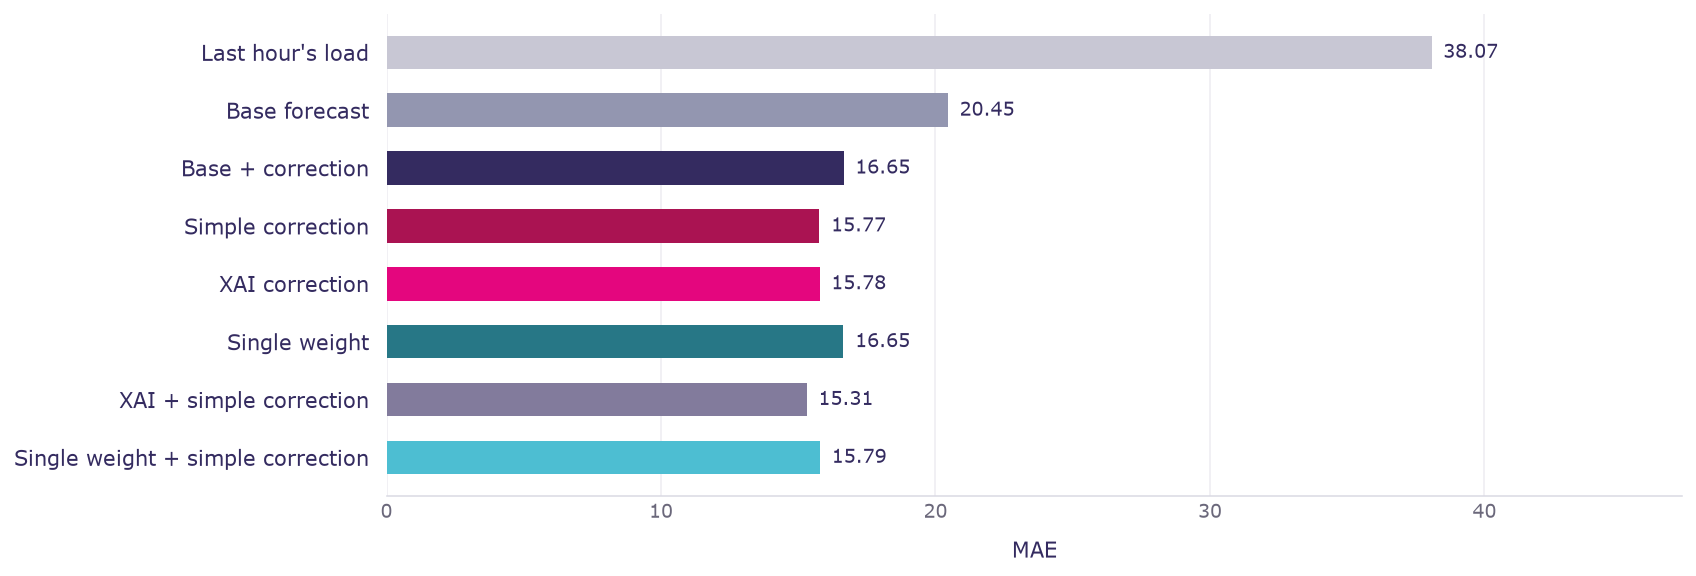

In [29]:
review_runs = {
    f"{COUNTRIES[d]} {cfg['datasets'][d]['test_year']}": {
        "frame": runs[d]["frame"], "forecasts": runs[d]["forecasts"],
        "components": runs[d]["components"], "weights": runs[d]["weights"],
        "thresholds": runs[d]["thresholds"],
    } for d in DATASETS
}
combined_cohort = PLOT_TITLES[combined_dataset]
review_runs[combined_cohort]["forecasts"] = {
    **review_runs[combined_cohort]["forecasts"], **combined_predictions,
}
review_labels = {**LABELS, **COMBINED_LABELS}
benchmark_methods = ("naive", "base", "residual", "hourly_bias", "credit_feedback", "matched_scalar", "xai_bias", "scalar_bias")
naive_rows = []
for cohort, run in review_runs.items():
    frame_review = run["frame"]
    y_review = frame_review.target_next_hour.to_numpy()
    naive_review = persistence_forecast(frame_review)
    np.testing.assert_array_equal(run["forecasts"]["naive"], naive_review)
    for scope, mask in scope_masks(frame_review, run["thresholds"]).items():
        if not mask.any():
            continue
        naive_mae = prediction_metrics(y_review[mask], naive_review[mask])["MAE"]
        for method in benchmark_methods:
            if method not in run["forecasts"]:
                continue
            scores = prediction_metrics(y_review[mask], np.asarray(run["forecasts"][method])[mask])
            naive_rows.append({"cohort": cohort, "method": method, "scope": scope, **scores,
                               "improvement_vs_naive_pct": 100 * (1 - scores["MAE"] / naive_mae) if naive_mae else np.nan})
naive_benchmark = pd.DataFrame(naive_rows)
naive_overall = naive_benchmark[naive_benchmark.scope.eq("overall")]
assert naive_benchmark.groupby(["cohort", "scope"]).n.nunique().eq(1).all()
display(naive_overall.assign(Method=lambda x: x.method.map(review_labels))[
    ["cohort", "Method", "n", "MAE", "RMSE", "improvement_vs_naive_pct"]
].rename(columns={"cohort": "Cohort", "n": "Hours", "improvement_vs_naive_pct": "MAE gain over persistence (%)"}))
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(len(review_runs), 1, figsize=(12, 4 * len(review_runs)), squeeze=False, layout='constrained')
    for ax, (cohort, run) in zip(axes[:, 0], review_runs.items()):
        values = naive_overall[naive_overall.cohort.eq(cohort)]
        analysis_barh(ax, [PLOT_LABELS[m] for m in values.method], values.MAE,
                      [PLOT_COLORS[m] for m in values.method])
        ax.set_xlabel('MAE')
    plt.show()


## 24. When does XAI change a forecast, and does it help?

Compare XAI with its own unweighted residual forecast. Each component changes by
`(weight − 1) × component`; their sum must reconstruct the forecast change.
Report component/forecast change frequency, magnitude, benefit and harm.
**Gain = unweighted absolute error − XAI absolute error**; its all-hour mean is MAE gain.

**Cancellation** is `1 − |sum of changes| / sum of absolute changes`, averaged only
when components change. Zero means aligned changes; one means complete cancellation.
The intercept is included. Cancellation alone is not evidence of a bug or causality.

Help/harm percentages are conditional on changed forecasts and undefined when none
change. The single-weight control distinguishes whole-correction weighting from
component weighting. These diagnostics do not select another model.


,Cohort,Hours,Components changed (%),Forecasts changed (%),Mean absolute change,Helped among changed (%),Harmed among changed (%),MAE gain over residual,Mean cancellation
0,Panama 2020,4273,98.2448,98.2448,2.8669,58.2182,41.7818,0.8741,0.2633


,Cohort,Mean difference from single weight,MAE(XAI) - MAE(single weight),Change correlation
0,Panama 2020,2.6089,-0.8712,0.4411


,Cohort,Component,Mean weight,Component changed (%),Mean absolute change
0,Panama 2020,Recent load,0.8020,38.5678,0.3506
1,Panama 2020,Seasonal load,0.7693,43.2951,0.2084
2,Panama 2020,Hour,0.7037,49.1692,0.5705
3,Panama 2020,Calendar,0.7405,47.9055,0.1751
4,Panama 2020,Weather,0.7356,45.8226,0.2254
5,Panama 2020,Load changes,0.7679,41.7271,0.7503
6,Panama 2020,Base forecast,0.6790,56.1900,0.6009
7,Panama 2020,Past errors,0.8752,26.5855,0.4944
8,Panama 2020,Offset,0.7199,45.2609,0.3441


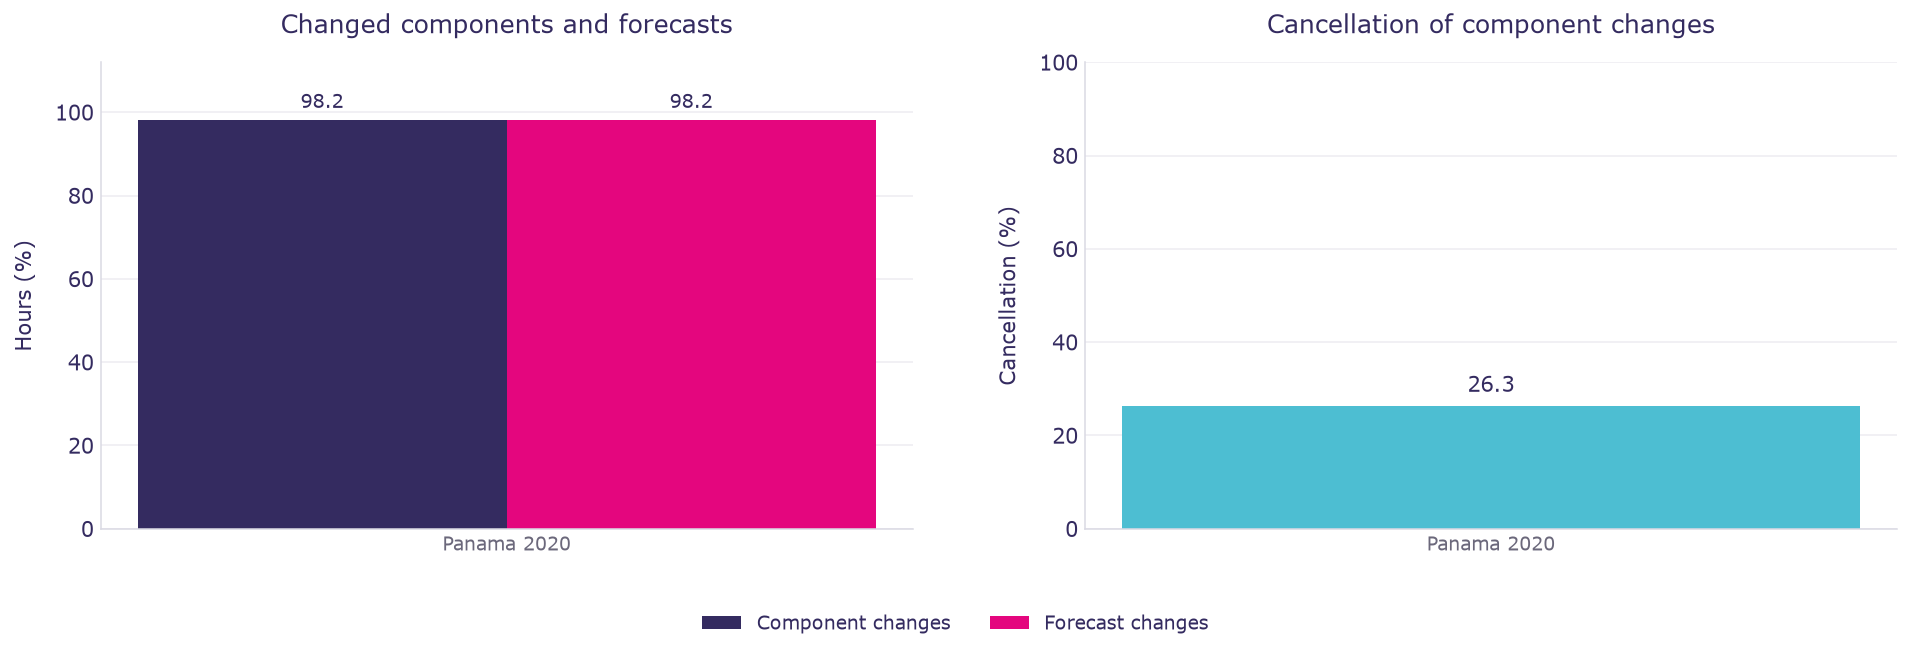

Panama 2020: XAI changed 98.2% of forecasts; among changed forecasts, 58.2% helped and 41.8% harmed. All-hour MAE gain over residual: +0.8741.
Panama 2020: second layer changed 98.3% of XAI forecasts; overall MAE change -0.4672. This is descriptive, not causal evidence.


In [30]:
diagnostic_details, diagnostic_rows, group_rows = {}, [], []
for cohort, run in review_runs.items():
    frame_review = run["frame"]
    predicted_review = run["forecasts"]["credit_feedback"]
    details, summary = correction_diagnostics(
        frame_review, run["components"], run["weights"], predicted_review,
        tolerance=DIAGNOSTIC_OPTIONS["change_tolerance"],
    )
    diagnostic_details[cohort] = details
    scalar_review = run["forecasts"]["matched_scalar"]
    xai_delta = predicted_review - frame_review.prediction_residual.to_numpy()
    scalar_delta = scalar_review - frame_review.prediction_residual.to_numpy()
    summary["mean_abs_difference_vs_scalar"] = float(abs(predicted_review - scalar_review).mean())
    summary["mae_difference_vs_scalar"] = float(
        abs(predicted_review - frame_review.target_next_hour.to_numpy()).mean()
        - abs(scalar_review - frame_review.target_next_hour.to_numpy()).mean()
    )
    summary["delta_correlation_vs_scalar"] = (float(np.corrcoef(xai_delta, scalar_delta)[0, 1])
        if min(np.std(xai_delta), np.std(scalar_delta)) > DIAGNOSTIC_OPTIONS["change_tolerance"] else np.nan)
    diagnostic_rows.append({"cohort": cohort, **summary})
    deltas = run["components"] * (run["weights"] - 1)
    for column in deltas:
        group_rows.append({"Cohort": cohort, "Component": GROUP_LABELS.get(column, column),
                           "Mean weight": run["weights"][column].mean(),
                           "Component changed (%)": 100 * deltas[column].abs().gt(DIAGNOSTIC_OPTIONS["change_tolerance"]).mean(),
                           "Mean absolute change": deltas[column].abs().mean()})
diagnostic_summary = pd.DataFrame(diagnostic_rows)
display(diagnostic_summary[["cohort", "n", "parts_changed_pct", "changed_pct", "mean_abs_change",
                            "helped_pct_when_changed", "harmed_pct_when_changed", "mae_gain_overall",
                            "mean_cancellation_when_parts_change"]].rename(columns={
    "cohort": "Cohort", "n": "Hours", "parts_changed_pct": "Components changed (%)",
    "changed_pct": "Forecasts changed (%)", "mean_abs_change": "Mean absolute change",
    "helped_pct_when_changed": "Helped among changed (%)", "harmed_pct_when_changed": "Harmed among changed (%)",
    "mae_gain_overall": "MAE gain over residual", "mean_cancellation_when_parts_change": "Mean cancellation",
}))
display(diagnostic_summary[["cohort", "mean_abs_difference_vs_scalar", "mae_difference_vs_scalar",
                            "delta_correlation_vs_scalar"]].rename(columns={
    "cohort": "Cohort", "mean_abs_difference_vs_scalar": "Mean difference from single weight",
    "mae_difference_vs_scalar": "MAE(XAI) - MAE(single weight)", "delta_correlation_vs_scalar": "Change correlation",
}))
display(pd.DataFrame(group_rows))
with plot_style("taltech", overrides=ANALYSIS_SIZES):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    positions = np.arange(len(diagnostic_summary))
    bars = axes[0].bar(positions - 0.18, diagnostic_summary.parts_changed_pct,
                       width=0.36, label='Component changes', color=PLOT_COLORS['residual'])
    axes[0].bar_label(bars, fmt='%.1f', padding=4, fontsize=10)
    bars = axes[0].bar(positions + 0.18, diagnostic_summary.changed_pct,
                       width=0.36, label='Forecast changes', color=PLOT_COLORS['credit_feedback'])
    axes[0].bar_label(bars, fmt='%.1f', padding=4, fontsize=10)
    labels = [cohort for cohort in diagnostic_summary.cohort]
    axes[0].set_xticks(positions, labels)
    axes[0].set(ylabel='Hours (%)', ylim=(0, 112), title='Changed components and forecasts')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=10)
    bars = axes[1].bar(positions, 100 * diagnostic_summary.mean_cancellation_when_parts_change,
                       color=PLOT_COLORS['lime'], width=0.55)
    axes[1].bar_label(bars, fmt='%.1f', padding=5, fontsize=11)
    axes[1].set_xticks(positions, labels)
    axes[1].set(ylabel='Cancellation (%)', ylim=(0, 100), title='Cancellation of component changes')
    for ax in axes:
        analysis_grid(ax, 'y')
    fig.tight_layout(pad=1.8, w_pad=4, rect=(0, 0.08, 1, 1))
    plt.show()

for row in diagnostic_summary.itertuples():
    print(f"{row.cohort}: XAI changed {row.changed_pct:.1f}% of forecasts; among changed forecasts, "
          f"{row.helped_pct_when_changed:.1f}% helped and {row.harmed_pct_when_changed:.1f}% harmed. "
          f"All-hour MAE gain over residual: {row.mae_gain_overall:+.4f}.")
post_change = combined_predictions["xai_bias"] - combined_predictions["credit_feedback"]
post_gain = abs(combined_actual - combined_predictions["credit_feedback"]) - abs(combined_actual - combined_predictions["xai_bias"])
post_active = abs(post_change) > DIAGNOSTIC_OPTIONS["change_tolerance"]
print(f"{PLOT_TITLES[combined_dataset]}: second layer changed {100 * post_active.mean():.1f}% of XAI forecasts; "
      f"overall MAE change {-post_gain.mean():+.4f}. This is descriptive, not causal evidence.")


## 25. Examples where XAI helped or harmed

After seven evaluation days, choose the **first changed forecast that helped** and
the **first that harmed** relative to unweighted residual correction. These are not
the largest gain and loss. Use equal-length windows around the selected targets.

The upper panels show forecasts; lower panels show the change contributed by weighting
each component. Positive bars raise the forecast; negative bars lower it. The intercept
may also change. Examples are descriptive and do not identify physical causes.


**Panama 2020**

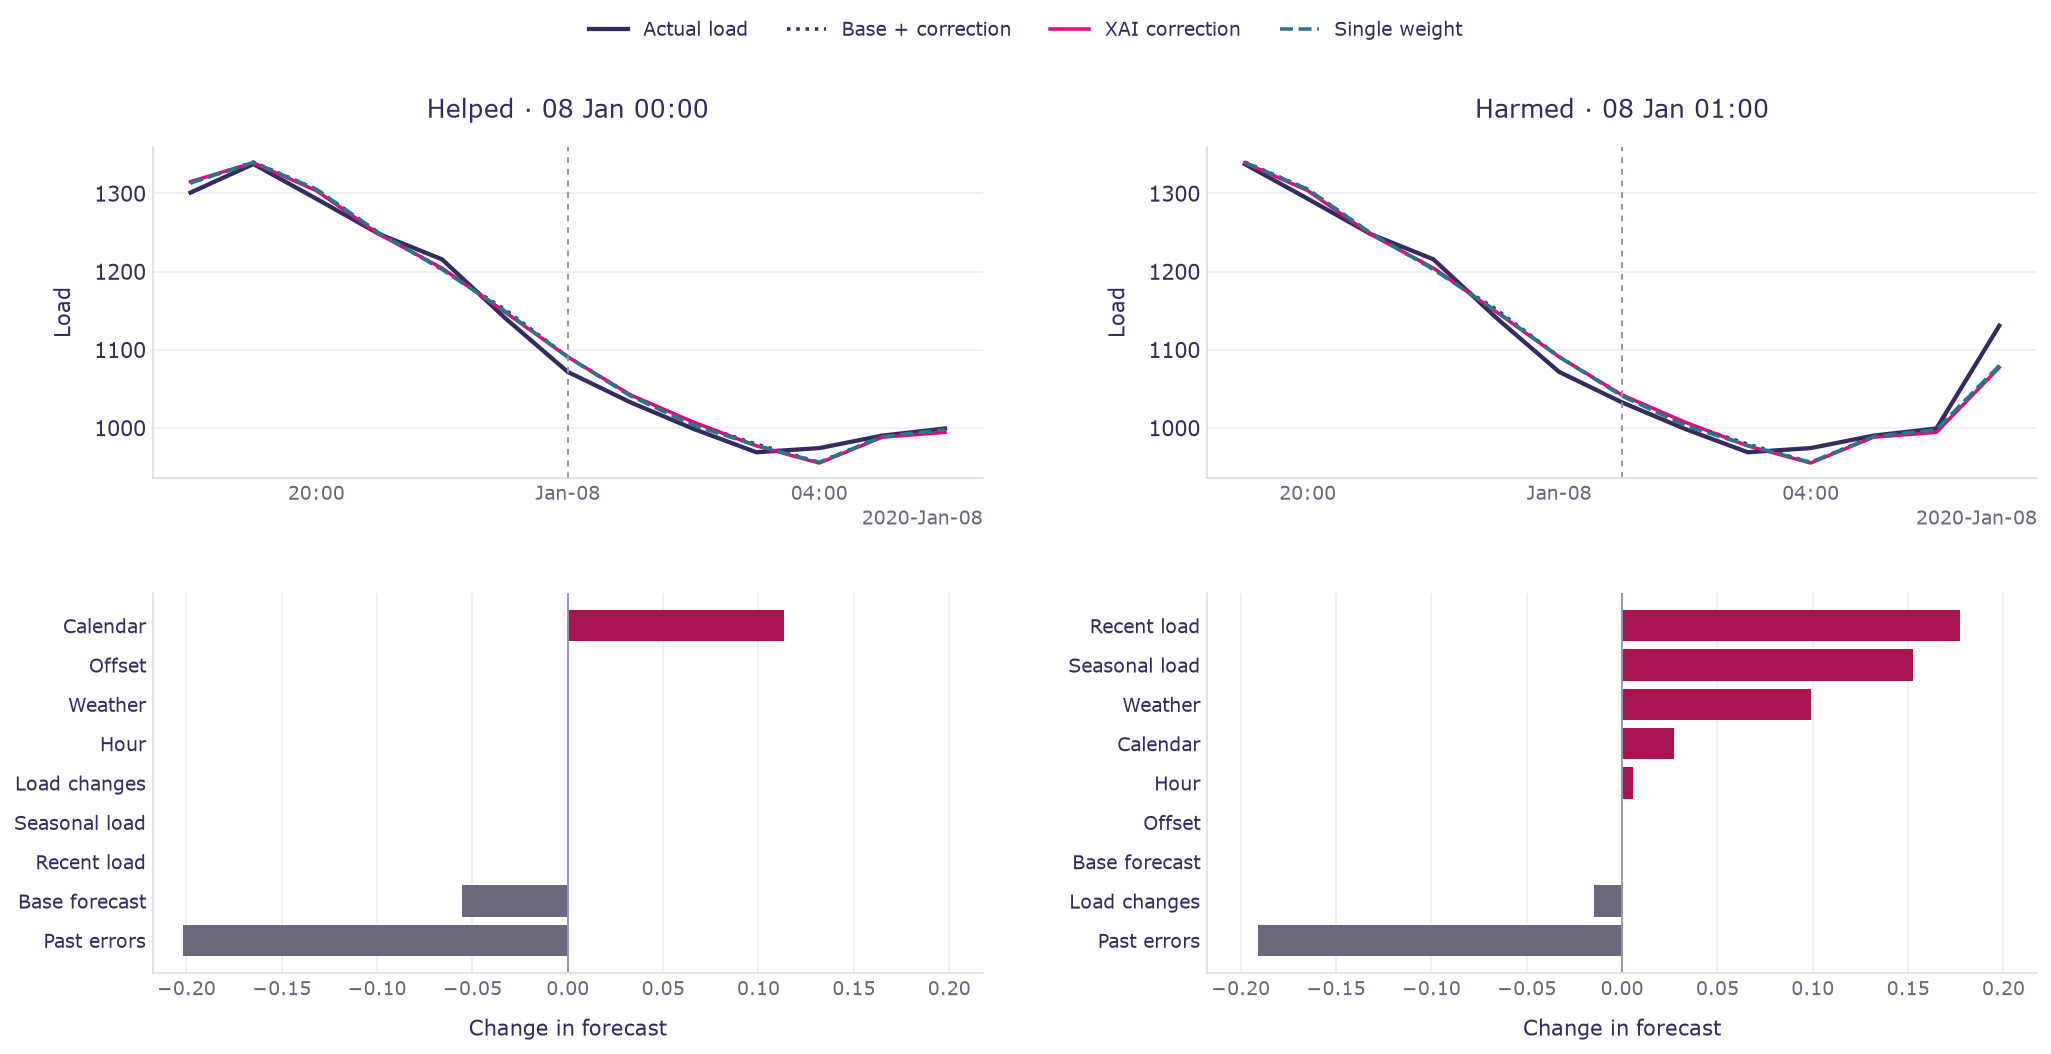

,Cohort,Example,Target time,Observed load,Residual forecast,XAI forecast,Gain over residual,Cancellation
0,Panama 2020,Helped,2020-01-08 00:00:00,1071.6841,1091.0077,1090.8637,0.1441,0.6112
1,Panama 2020,Harmed,2020-01-08 01:00:00,1032.7158,1041.9592,1042.2152,-0.2560,0.6164


In [31]:
diagnostic_case_rows = []
for cohort, run in review_runs.items():
    frame_review, details = run['frame'], diagnostic_details[cohort]
    eligible = frame_review.target_time.ge(frame_review.target_time.min() + pd.Timedelta(days=EXAMPLE_OFFSET_DAYS))
    selected = []
    for label, mask in (('Helped', details.helped), ('Harmed', details.harmed)):
        candidates = frame_review.index[eligible & details.prediction_changed & mask]
        if len(candidates):
            selected.append((label, candidates[0]))
    if not selected:
        print(cohort, '- no eligible examples.')
        continue
    display(Markdown(f"**{cohort}**"))
    with plot_style("taltech", overrides=ANALYSIS_SIZES):
        fig, axes = plt.subplots(2, len(selected), figsize=(15, 8), squeeze=False,
                                 gridspec_kw={'height_ratios': [1.0, 1.15]})
        for col, (label, index) in enumerate(selected):
            target = frame_review.loc[index, 'target_time']
            window = frame_review.target_time.between(
                target - pd.Timedelta(hours=DIAGNOSTIC_OPTIONS['case_hours_before']),
                target + pd.Timedelta(hours=DIAGNOSTIC_OPTIONS['case_hours_after']))
            times = frame_review.loc[window, 'target_time']
            axes[0, col].plot(times, frame_review.loc[window, 'target_next_hour'],
                              color=TALTECH_COLORS["ink"], label='Actual load', linewidth=2.2)
            for method, style in [('residual', ':'), ('credit_feedback', '-'), ('matched_scalar', '--')]:
                axes[0, col].plot(times, np.asarray(run['forecasts'][method])[window],
                                  label=PLOT_LABELS[method], color=PLOT_COLORS[method], linestyle=style)
            axes[0, col].axvline(target, color=TALTECH_COLORS["line"], linestyle=(0, (3, 3)), linewidth=1)
            outcome = 'Helped' if label == 'Helped' else 'Harmed'
            axes[0, col].set(title=f'{outcome} · {target:%d %b %H:%M}', ylabel='Load')
            analysis_dates(axes[0, col], maxticks=5)
            analysis_grid(axes[0, col], 'y')
            changes = (run['components'].loc[index] * (run['weights'].loc[index] - 1)).sort_values()
            axes[1, col].barh([PLOT_GROUPS.get(k, k) for k in changes.index], changes,
                color=[PLOT_COLORS['feature_ablation'] if v < 0 else PLOT_COLORS['hourly_bias'] for v in changes])
            axes[1, col].axvline(0, color=TALTECH_COLORS["line"], linewidth=1)
            axes[1, col].set_xlabel('Change in forecast')
            axes[1, col].tick_params(axis='y', labelsize=10)
            analysis_grid(axes[1, col])
            diagnostic_case_rows.append({'Cohort': cohort, 'Example': label, 'Target time': target,
                'Observed load': frame_review.loc[index, 'target_next_hour'],
                'Residual forecast': run['forecasts']['residual'][index],
                'XAI forecast': run['forecasts']['credit_feedback'][index],
                'Gain over residual': details.loc[index, 'gain_vs_residual'],
                'Cancellation': details.loc[index, 'cancellation_share']})
        load_min = min(ax.get_ylim()[0] for ax in axes[0])
        load_max = max(ax.get_ylim()[1] for ax in axes[0])
        change_limit = max(max(abs(value) for value in ax.get_xlim()) for ax in axes[1])
        for ax in axes[0]:
            ax.set_ylim(load_min, load_max)
        for ax in axes[1]:
            ax.set_xlim(-change_limit, change_limit)
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center',
                    bbox_to_anchor=(0.5, 0.96), ncol=4, fontsize=10)
        fig.tight_layout(pad=1.8, w_pad=4, h_pad=3, rect=(0, 0, 1, 0.91))
        plt.show()
diagnostic_cases = pd.DataFrame(diagnostic_case_rows)
display(diagnostic_cases)


## 26. Research-question summary

Connect each research question with its comparison and limitations. Distinguish
development selection, retrospective evaluation, the combined-method extension and
descriptive diagnostics. All current rows concern Panama.

The study does not measure human interpretability or economic benefit. Absence of a
clear difference is not evidence of equivalence. Conclusions remain conditional on
the documented availability, unit and timestamp assumptions.


In [32]:
research_rows = []
for dataset in DATASETS:
    row = primary_intervals[primary_intervals.dataset.eq(dataset) & primary_intervals.scope.eq("overall")].iloc[0]
    result = ("Clearly lower XAI MAE" if row.adjusted_low > 0 else
              "Clearly lower simple-correction MAE" if row.adjusted_high < 0 else "No clear overall MAE difference")
    research_rows.append({"Question/check": "RQ1: added XAI benefit", "Comparison": "XAI versus simple correction",
                          "Data": PLOT_TITLES[dataset], "Result": result,
                          "Limitation": "Retrospective; time-block intervals; assumed immediate availability"})
    rows = xai_primary_intervals[xai_primary_intervals.dataset.eq(dataset)
                                 & xai_primary_intervals.scope.eq("overall")
                                 & xai_primary_intervals.B.isin(EXPLAINERS)]
    clear = rows[(rows.adjusted_low > 0) | (rows.adjusted_high < 0)]
    times = xai_timing[xai_timing.dataset.eq(dataset) & xai_timing.method.isin(EXPLAINERS)].set_index("method").total_seconds
    result = "No clear overall MAE difference" if clear.empty else "Clear MAE difference in at least one pair"
    research_rows.append({"Question/check": "RQ2: explanation method", "Comparison": "TreeSHAP, LIME, group ablation",
                          "Data": PLOT_TITLES[dataset],
                          "Result": result + "; fastest explainer: " + XAI_LABELS[times.idxmin()],
                          "Limitation": "Shared combination rule and TreeSHAP-selected settings; retrospective"})
claim = combined_primary_intervals[combined_primary_intervals.scope.eq("overall")
                                   & combined_primary_intervals.A.eq("xai_bias")
                                   & combined_primary_intervals.B.isin(["hourly_bias", "scalar_bias"])]
assert len(claim) == 2
research_rows.append({"Question/check": "RQ1: combined-method extension", "Comparison": "XAI + bias and matched control",
                      "Data": PLOT_TITLES[combined_dataset],
                      "Result": "Clear advantage over both controls" if claim.adjusted_high.lt(0).all()
                                else "No clear overall advantage over both controls",
                      "Limitation": "Same previously examined evaluation period; no independent confirmation"})
rapid = xai_primary_intervals[xai_primary_intervals.scope.ne("overall")]
clear_rapid = rapid[(rapid.adjusted_low > 0) | (rapid.adjusted_high < 0)]
rapid_findings = [f"{COUNTRIES[r.dataset]}, {scope_labels[r.scope]}: "
                  f"{XAI_LABELS[r.A if r.adjusted_high < 0 else r.B]}"
                  for r in clear_rapid.itertuples()]
research_rows.append({"Question/check": "RQ1/RQ2: rapid changes", "Comparison": "Increase/decrease hours",
                      "Data": "; ".join(PLOT_TITLES.values()),
                      "Result": "; ".join(dict.fromkeys(rapid_findings)) or "No clear difference",
                      "Limitation": "Retrospective subgroups do not predict when to switch methods"})
for cohort, values in naive_overall.groupby("cohort", sort=False):
    best = values.loc[values.MAE.idxmin()]
    research_rows.append({"Question/check": "Naive benchmark", "Comparison": "Persistence versus forecasts/corrections",
                          "Data": cohort,
                          "Result": f"Lowest displayed MAE: {review_labels[best.method]}; gain over persistence {best.improvement_vs_naive_pct:.2f}%",
                          "Limitation": "Descriptive comparison on a common mask"})
research_summary = pd.DataFrame(research_rows)
with pd.option_context("display.max_colwidth", None):
    display(research_summary)
print("Contribution and weight diagnostics describe the result; they do not establish causality.")


,Question/check,Comparison,Data,Result,Limitation
0,RQ1: added XAI benefit,XAI versus simple correction,Panama 2020,No clear overall MAE difference,Retrospective; time-block intervals; assumed immediate availability
1,RQ2: explanation method,"TreeSHAP, LIME, group ablation",Panama 2020,No clear overall MAE difference; fastest explainer: TreeSHAP,Shared combination rule and TreeSHAP-selected settings; retrospective
2,RQ1: combined-method extension,XAI + bias and matched control,Panama 2020,Clear advantage over both controls,Same previously examined evaluation period; no independent confirmation
3,RQ1/RQ2: rapid changes,Increase/decrease hours,Panama 2020,No clear difference,Retrospective subgroups do not predict when to switch methods
4,Naive benchmark,Persistence versus forecasts/corrections,Panama 2020,Lowest displayed MAE: XAI + simple correction; gain over persistence 59.79%,Descriptive comparison on a common mask


Contribution and weight diagnostics describe the result; they do not establish causality.


## 27. Conclusions and limits

Generate conclusions from this run. Overall accuracy, rapid changes and harmful
corrections can give different answers. A comparison on one previously examined
Panama period does not establish general superiority or transfer to another country.
The combined method reuses the same evaluation period and is not a new confirmation.

- Load/error availability is immediate by assumption; the 24-hour weather shift does
  not represent MERRA-2 release timing. Units and some interval metadata are unconfirmed.
- Evaluation covers the available 2020 source period, not a complete year. Later months
  are unavailable and are not filled in or scored.
- Explainers share TreeSHAP-selected correction settings. Sampling sizes are fixed;
  runtime depends on hardware and load.
- The unexplained remainder stays unchanged. Exact reconstruction after adding it
  back does not demonstrate explanation quality.
- Contributions do not establish causality; interpretability and economic value are
  not evaluated. Intervals crossing zero do not establish equivalence.

Intermediate data and results remain in memory, including `selection`, `runs`,
`metrics`, `monthly`, `intervals` and the `combined_*` tables.


In [33]:
for dataset in DATASETS:
    values = overall[overall.dataset.eq(dataset)].set_index("method")
    interval = primary_intervals[
        primary_intervals.dataset.eq(dataset) & primary_intervals.scope.eq("overall")
    ].iloc[0]
    conclusion = ("Clearly lower overall XAI MAE." if interval.adjusted_low > 0 else
                  "Clearly lower overall simple-correction MAE." if interval.adjusted_high < 0 else
                  "No clear overall MAE difference.")
    print(f"{PLOT_TITLES[dataset]}: simple MAE {values.loc['hourly_bias', 'MAE']:.4f}; "
          f"XAI MAE {values.loc['credit_feedback', 'MAE']:.4f}.")
    print(conclusion)
    print(f"Adjusted interval, simple - XAI: [{interval.adjusted_low:.4f}, {interval.adjusted_high:.4f}]")
    print("Explanation-method comparison:")
    for row in xai_primary_intervals[
        xai_primary_intervals.dataset.eq(dataset) & xai_primary_intervals.scope.eq("overall")
    ].itertuples():
        verdict = ("clearly lower MAE: " + XAI_LABELS[row.A] if row.adjusted_high < 0 else
                   "clearly lower MAE: " + XAI_LABELS[row.B] if row.adjusted_low > 0 else
                   "no clear MAE difference")
        print(f"  {XAI_LABELS[row.A]} / {XAI_LABELS[row.B]}: {verdict}.")
    print("Added batch computation time (s):")
    print(xai_timing[xai_timing.dataset.eq(dataset)][["method", "total_seconds"]]
          .assign(method=lambda x: x.method.map(XAI_LABELS)).to_string(index=False))
    print("Mean absolute unexplained remainder:")
    print(xai_checks[xai_checks.dataset.eq(dataset)][["method", "native_gap_mae"]]
          .assign(method=lambda x: x.method.map(XAI_LABELS)).to_string(index=False))
print(f"\n{PLOT_TITLES[combined_dataset]}: retrospective combined-method extension")
primary_claim = combined_primary_intervals[
    combined_primary_intervals.scope.eq("overall") & combined_primary_intervals.A.eq("xai_bias")
    & combined_primary_intervals.B.isin(["hourly_bias", "scalar_bias"])
]
assert len(primary_claim) == 2
print("Clear overall advantage over both controls." if primary_claim.adjusted_high.lt(0).all()
      else "A clear overall advantage over both controls was not established.")
for row in combined_primary_intervals[combined_primary_intervals.scope.eq("overall")].itertuples():
    print(f"{COMBINED_LABELS[row.A]} / {COMBINED_LABELS[row.B]}: MAE difference {row.difference:+.4f}; "
          f"adjusted interval [{row.adjusted_low:.4f}, {row.adjusted_high:.4f}].")
print("An extra-layer benefit alone does not establish an XAI advantage over the matched no-XAI control.")
print("\nPersistence benchmark:")
for cohort, values in naive_overall.groupby("cohort", sort=False):
    print(cohort + ":")
    for row in values.itertuples():
        print(f"  {review_labels[row.method]}: MAE {row.MAE:.4f}; gain over persistence {row.improvement_vs_naive_pct:.2f}%.")
print("Limits: one previously examined Panama period, incomplete 2020 coverage, assumed immediate load availability,")
print("weather timing inconsistent with MERRA-2 release delay, and unconfirmed source metadata.")


Panama 2020: simple MAE 15.7702; XAI MAE 15.7765.
No clear overall MAE difference.
Adjusted interval, simple - XAI: [-0.1341, 0.1175]
Explanation-method comparison:
  LIME / TreeSHAP: no clear MAE difference.
  Group ablation / TreeSHAP: no clear MAE difference.
  Group ablation / LIME: no clear MAE difference.
  TreeSHAP / Simple correction: no clear MAE difference.
  LIME / Simple correction: no clear MAE difference.
  Group ablation / Simple correction: no clear MAE difference.
Added batch computation time (s):
           method  total_seconds
Simple correction         0.0673
         TreeSHAP         3.7739
             LIME        54.5568
   Group ablation         7.9830
Mean absolute unexplained remainder:
        method  native_gap_mae
      TreeSHAP          0.0000
          LIME          7.2113
Group ablation          6.0111

Panama 2020: retrospective combined-method extension
Clear overall advantage over both controls.
XAI + simple correction / Simple correction: MAE differe